In [119]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')


In [120]:
df=pd.read_csv("TCS_Final_ML_Dataset.csv")

print("shape",df.shape)
df.head(5)

shape (2100, 32)


,Date,Open,High,Low,Close,Volume,Daily_Return,Open_Close_Diff,High_Low_Diff,MA_10,...,Close_Lag_10,Close_Lag_20,NIFTY_Close,NIFTY_Return,NIFTY_Volatility,CPI_Inflation,GDP_Growth,Target_Price,Target_Return,Target_Class
0,2018-04-02,1420.000000,1457.000000,1420.000000,1454.824951,1662988,2.123440,34.824951,37.000000,1422.564990,...,1434.849976,1517.525024,10211.799805,0.969968,0.916421,4.58,6.795384,1455.625000,0.054993,HOLD
1,2018-04-03,1446.050049,1464.949951,1446.050049,1455.625000,1937290,0.054993,9.574951,18.899902,1426.842493,...,1412.849976,1518.849976,10245.000000,0.325116,0.920673,4.58,6.795384,1455.449951,-0.012026,HOLD
2,2018-04-04,1464.724976,1467.000000,1446.000000,1455.449951,2841820,-0.012026,-9.275024,21.000000,1430.837488,...,1415.500000,1552.925049,10128.400391,-1.138112,0.930665,4.58,6.795384,1478.974976,1.616340,BUY
3,2018-04-05,1463.275024,1481.875000,1460.175049,1478.974976,1809424,1.616340,15.699951,21.699951,1435.492480,...,1432.425049,1521.400024,10325.150391,1.942557,1.008139,4.58,6.795384,1475.150024,-0.258622,HOLD
4,2018-04-06,1477.000000,1480.000000,1463.275024,1475.150024,1129018,-0.258622,-1.849976,16.724976,1440.169983,...,1428.375000,1513.724976,10331.599609,0.062461,0.982018,4.58,6.795384,1461.949951,-0.894829,HOLD


In [121]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 2100
Number of columns: 32


In [122]:
df.columns

Index(['Date', 'Open', 'High', 'Low', 'Close', 'Volume', 'Daily_Return',
       'Open_Close_Diff', 'High_Low_Diff', 'MA_10', 'MA_20', 'MA_50', 'RSI',
       'MACD', 'MACD_Signal', 'BB_Upper', 'BB_Middle', 'BB_Lower',
       'Volume_Change', 'Volume_MA', 'Close_Lag_1', 'Close_Lag_5',
       'Close_Lag_10', 'Close_Lag_20', 'NIFTY_Close', 'NIFTY_Return',
       'NIFTY_Volatility', 'CPI_Inflation', 'GDP_Growth', 'Target_Price',
       'Target_Return', 'Target_Class'],
      dtype='object')

In [123]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2100 entries, 0 to 2099
Data columns (total 32 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Date              2100 non-null   object 
 1   Open              2100 non-null   float64
 2   High              2100 non-null   float64
 3   Low               2100 non-null   float64
 4   Close             2100 non-null   float64
 5   Volume            2100 non-null   int64  
 6   Daily_Return      2100 non-null   float64
 7   Open_Close_Diff   2100 non-null   float64
 8   High_Low_Diff     2100 non-null   float64
 9   MA_10             2100 non-null   float64
 10  MA_20             2100 non-null   float64
 11  MA_50             2100 non-null   float64
 12  RSI               2100 non-null   float64
 13  MACD              2100 non-null   float64
 14  MACD_Signal       2100 non-null   float64
 15  BB_Upper          2100 non-null   float64
 16  BB_Middle         2100 non-null   float64


In [124]:
print("Invalid dates:", df["Date"].isna().sum())

Invalid dates: 0


**Sort Chronologically**

In [125]:
df = df.sort_values("Date").reset_index(drop=True)

display(df[["Date", "Close"]].head())
display(df[["Date", "Close"]].tail())

,Date,Close
0,2018-04-02,1454.824951
1,2018-04-03,1455.625000
2,2018-04-04,1455.449951
3,2018-04-05,1478.974976
4,2018-04-06,1475.150024


,Date,Close
2095,2026-09-23,2089.600098
2096,2026-09-24,2087.000000
2097,2026-09-25,2082.000000
2098,2026-09-28,2070.699951
2099,2026-09-29,2032.400024


**Missing Value Analysis**

In [126]:
missing = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percentage": (
        df.isna().mean() * 100
    ).round(2)
})

missing = missing.sort_values(
    "Missing_Count",
    ascending=False
)

display(missing)

,Missing_Count,Missing_Percentage
Date,0,0.0
Open,0,0.0
High,0,0.0
Low,0,0.0
Close,0,0.0
Volume,0,0.0
Daily_Return,0,0.0
Open_Close_Diff,0,0.0
High_Low_Diff,0,0.0
MA_10,0,0.0


**Visualize missing Values**

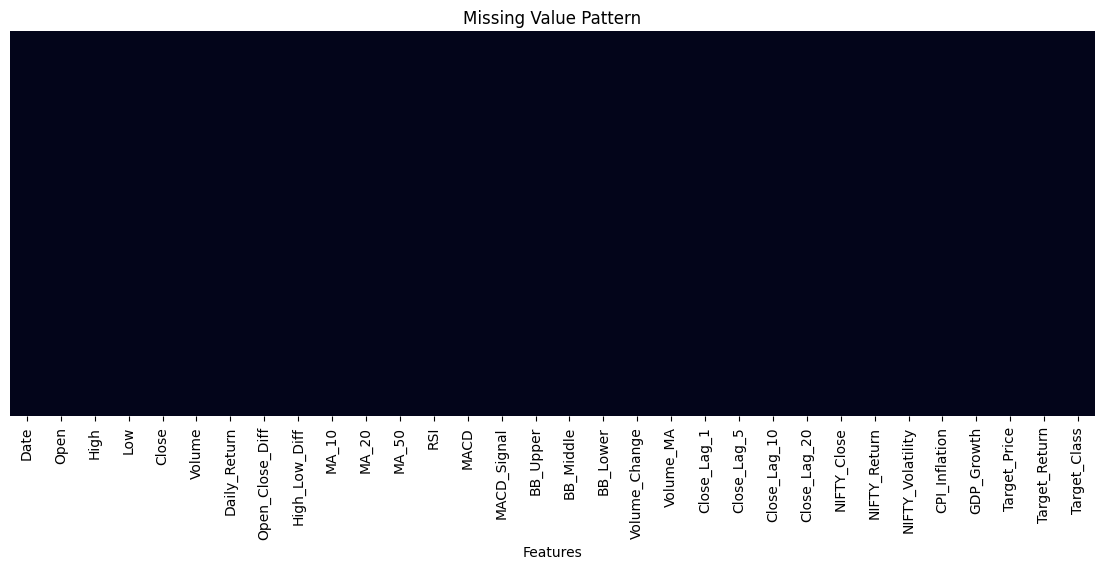

In [127]:
plt.figure(figsize=(14, 5))

sns.heatmap(
    df.isna(),
    cbar=False,
    yticklabels=False
)

plt.title("Missing Value Pattern")
plt.xlabel("Features")
plt.show()

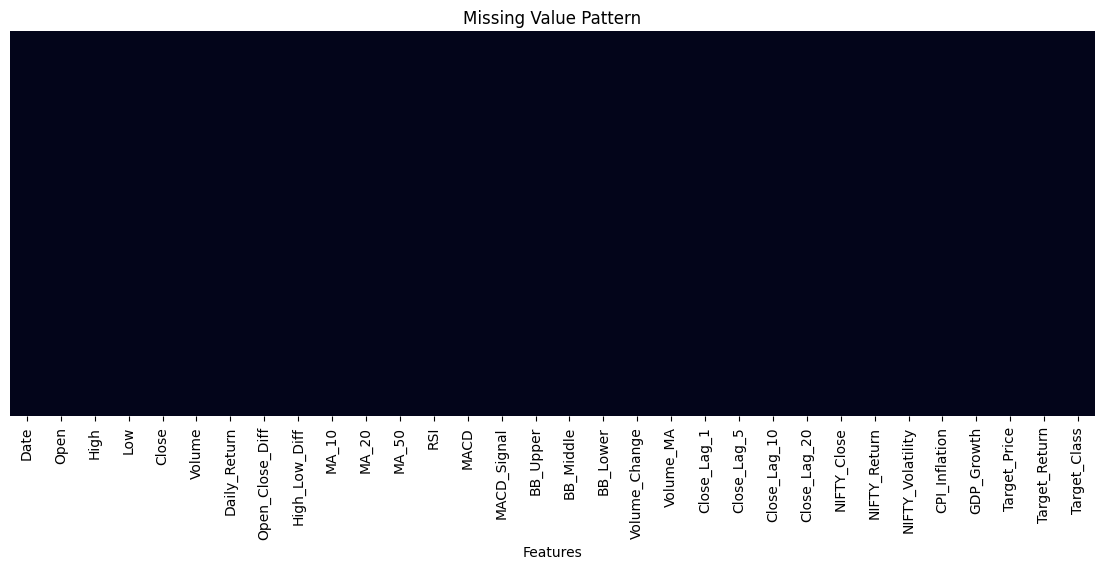

In [128]:
plt.figure(figsize=(14, 5))

sns.heatmap(
    df.isna(),
    cbar=False,
    yticklabels=False
)

plt.title("Missing Value Pattern")
plt.xlabel("Features")
plt.show()

In [129]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [130]:
numeric_df=df.select_dtypes(include=np.number)
display(numeric_df.describe())

,Open,High,Low,Close,Volume,Daily_Return,Open_Close_Diff,High_Low_Diff,MA_10,MA_20,...,Close_Lag_5,Close_Lag_10,Close_Lag_20,NIFTY_Close,NIFTY_Return,NIFTY_Volatility,CPI_Inflation,GDP_Growth,Target_Price,Target_Return
count,2100.000000,2100.000000,2100.000000,2100.000000,2.100000e+03,2100.000000,2100.000000,2100.000000,2100.000000,2100.000000,...,2100.000000,2100.000000,2100.000000,2100.000000,2100.000000,2100.000000,2100.000000,2100.000000,2100.000000,2100.000000
mean,2972.689929,3000.767460,2942.676912,2970.895986,2.900668e+06,0.028948,-1.793943,58.090548,2969.479396,2967.748208,...,2969.334069,2967.622879,2963.968533,17511.643702,0.044296,0.906383,4.576700,5.645614,2971.179688,0.028363
std,752.614880,756.949974,748.746317,752.685077,1.857103e+06,1.551182,38.911053,28.833442,752.912664,753.536334,...,755.225025,757.902803,763.071070,5409.089465,1.068596,0.563480,1.947359,4.490501,752.225506,1.550623
min,1420.000000,1457.000000,1420.000000,1454.824951,0.000000e+00,-9.410349,-193.500000,0.000000,1422.564990,1442.518738,...,1408.500000,1408.500000,1408.500000,0.000000,-12.980466,0.000000,0.250000,-5.777726,1455.449951,-9.410349
25%,2199.937439,2224.750000,2175.799988,2198.799927,1.783376e+06,-0.756980,-24.399963,38.124939,2192.939978,2178.722479,...,2198.799927,2198.799927,2191.699951,11797.537842,-0.448450,0.605437,3.160000,6.453853,2198.799927,-0.756980
50%,3154.750000,3177.500000,3125.199951,3150.500000,2.459974e+06,0.000000,-2.300049,51.574829,3155.517517,3164.484998,...,3150.500000,3150.500000,3150.500000,17523.774414,0.063592,0.768825,4.870000,6.795384,3150.500000,0.000000
75%,3502.475037,3534.149902,3480.025024,3502.524963,3.403215e+06,0.803923,19.962463,71.712463,3504.476239,3498.421231,...,3502.524963,3502.524963,3502.524963,23123.162598,0.595770,1.021518,6.210000,7.609365,3502.524963,0.803923
max,4576.000000,4592.250000,4512.000000,4553.750000,2.290380e+07,9.845081,203.950195,313.949951,4513.294922,4502.377490,...,4553.750000,4553.750000,4553.750000,26328.550781,8.763210,5.596263,7.790000,9.689592,4553.750000,9.845081


**TARGET CLASSIFICATION ANALYSIS**

In [131]:
target_counts = df["Target_Class"].value_counts()

print(target_counts)

Target_Class
HOLD    1247
BUY      436
SELL     417
Name: count, dtype: int64


In [132]:
target_percentage = (
    df["Target_Class"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

display(target_percentage)

,proportion
Target_Class,
HOLD,59.38
BUY,20.76
SELL,19.86


**BUY/HOLD/SELL visualization**

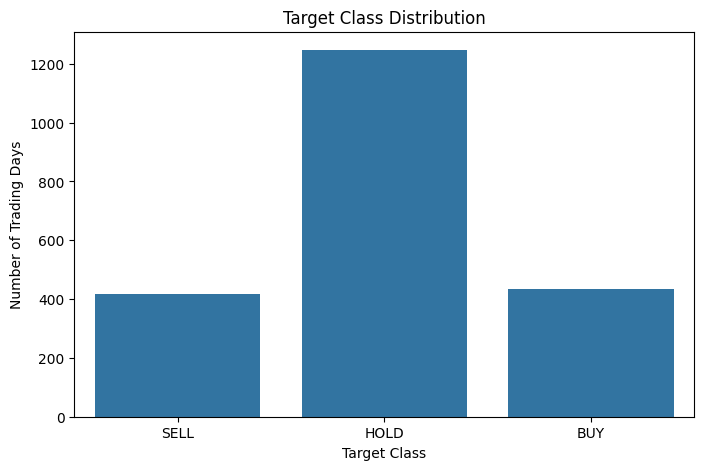

In [133]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Target_Class",
    order=["SELL", "HOLD", "BUY"]
)

plt.title("Target Class Distribution")
plt.xlabel("Target Class")
plt.ylabel("Number of Trading Days")
plt.show()

**Target Class Over Time**

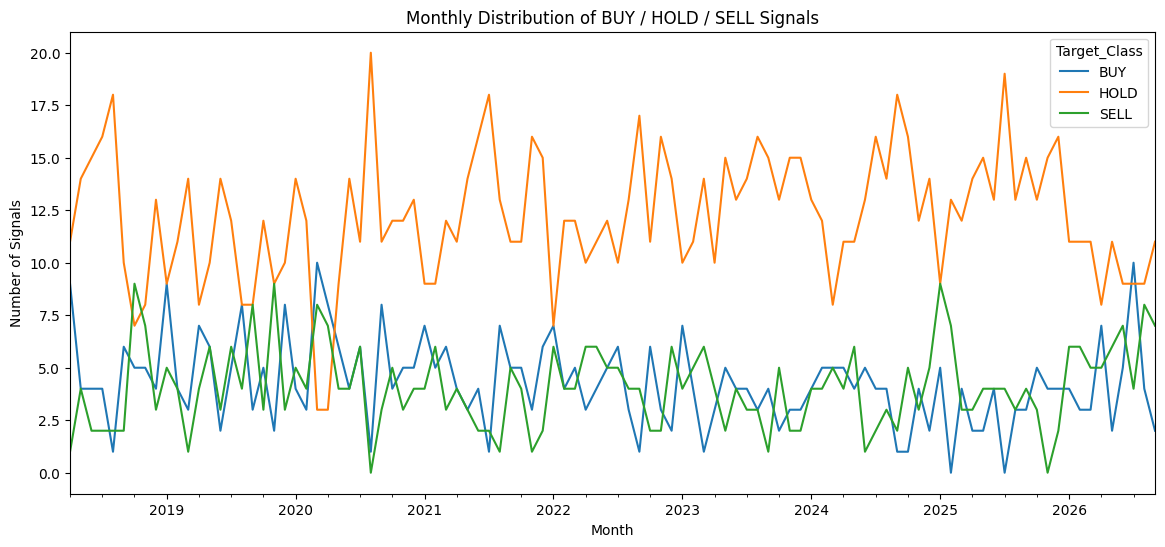

In [134]:
df["Date"] = pd.to_datetime(df["Date"])

target_time = (
    df.groupby(
        [df["Date"].dt.to_period("M"), "Target_Class"]
    )
    .size()
    .unstack(fill_value=0)
)

target_time.plot(
    figsize=(14, 6)
)

plt.title("Monthly Distribution of BUY / HOLD / SELL Signals")
plt.xlabel("Month")
plt.ylabel("Number of Signals")

plt.show()

In [135]:
print(df["Target_Return"].describe())

count    2100.000000
mean        0.028363
std         1.550623
min        -9.410349
25%        -0.756980
50%         0.000000
75%         0.803923
max         9.845081
Name: Target_Return, dtype: float64


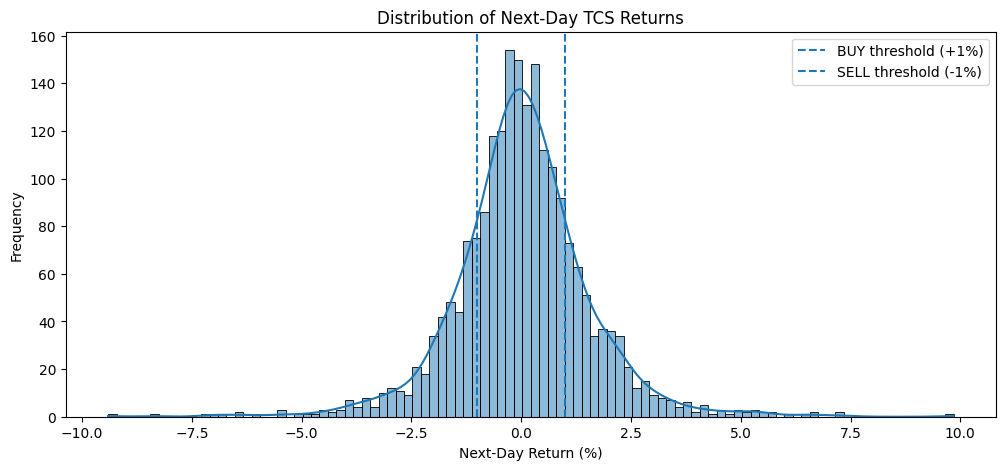

In [136]:
plt.figure(figsize=(12, 5))

sns.histplot(
    df["Target_Return"],
    bins=100,
    kde=True
)

plt.axvline(
    1,
    linestyle="--",
    label="BUY threshold (+1%)"
)

plt.axvline(
    -1,
    linestyle="--",
    label="SELL threshold (-1%)"
)

plt.title("Distribution of Next-Day TCS Returns")
plt.xlabel("Next-Day Return (%)")
plt.ylabel("Frequency")

plt.legend()
plt.show()

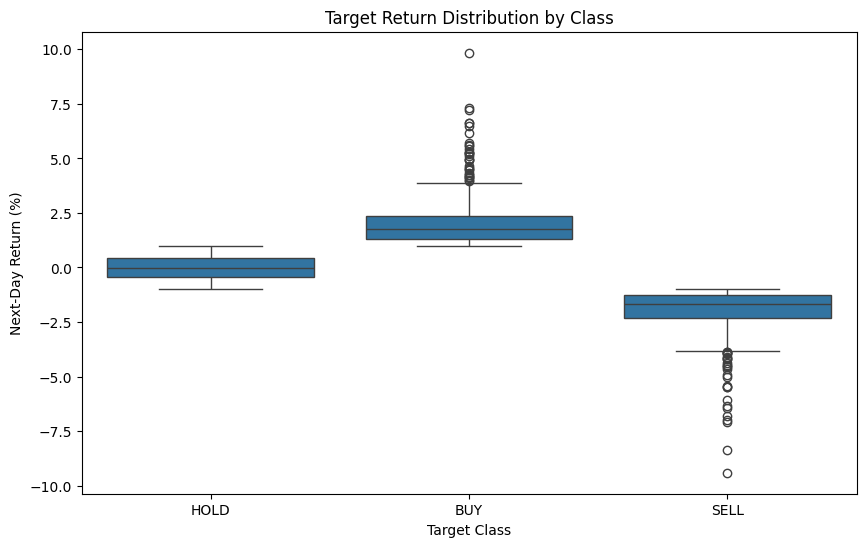

In [137]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Target_Class",
    y="Target_Return"
)

plt.title("Target Return Distribution by Class")
plt.xlabel("Target Class")
plt.ylabel("Next-Day Return (%)")

plt.show()

In [138]:
market_cols = [
    "Open",
    "High",
    "Low",
    "Close",
    "Volume",
    "Daily_Return"
]

display(df[market_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
Open,2100.0,2.972690e+03,7.526149e+02,1420.000000,2.199937e+03,3.154750e+03,3.502475e+03,4.576000e+03
High,2100.0,3.000767e+03,7.569500e+02,1457.000000,2.224750e+03,3.177500e+03,3.534150e+03,4.592250e+03
Low,2100.0,2.942677e+03,7.487463e+02,1420.000000,2.175800e+03,3.125200e+03,3.480025e+03,4.512000e+03
Close,2100.0,2.970896e+03,7.526851e+02,1454.824951,2.198800e+03,3.150500e+03,3.502525e+03,4.553750e+03
Volume,2100.0,2.900668e+06,1.857103e+06,0.000000,1.783376e+06,2.459974e+06,3.403215e+06,2.290380e+07
Daily_Return,2100.0,2.894815e-02,1.551182e+00,-9.410349,-7.569796e-01,0.000000e+00,8.039226e-01,9.845081e+00


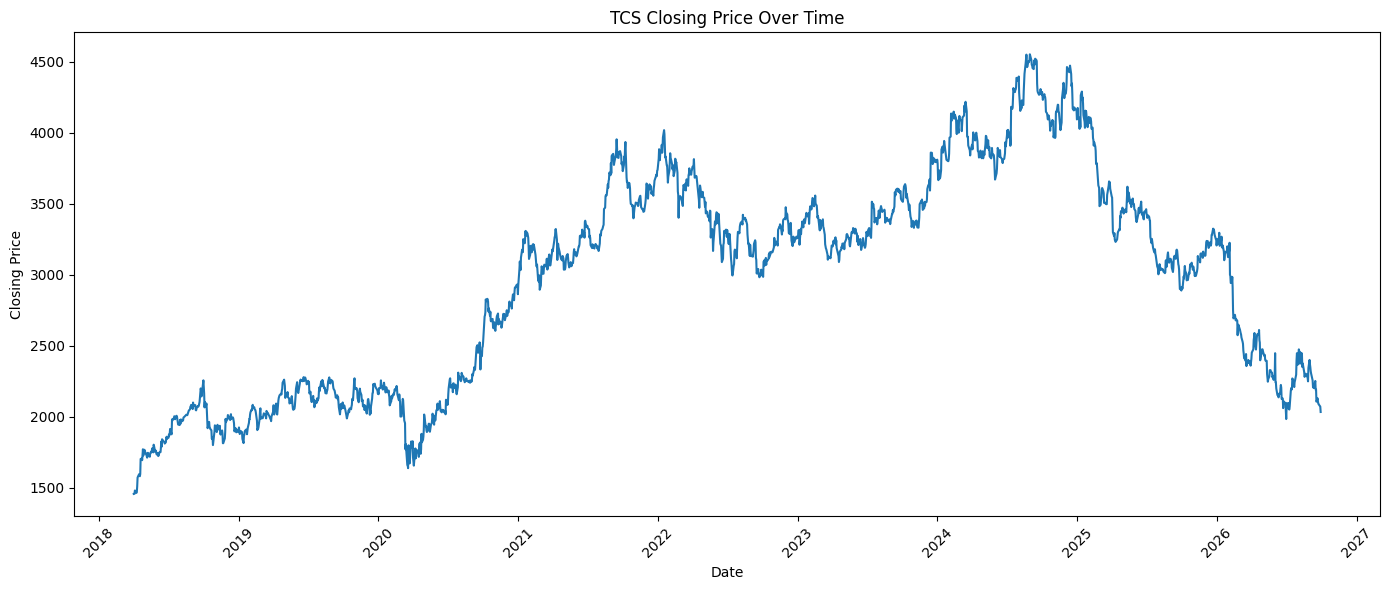

In [139]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["Date"],
    df["Close"]
)

plt.title("TCS Closing Price Over Time")
plt.xlabel("Date")
plt.ylabel("Closing Price")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

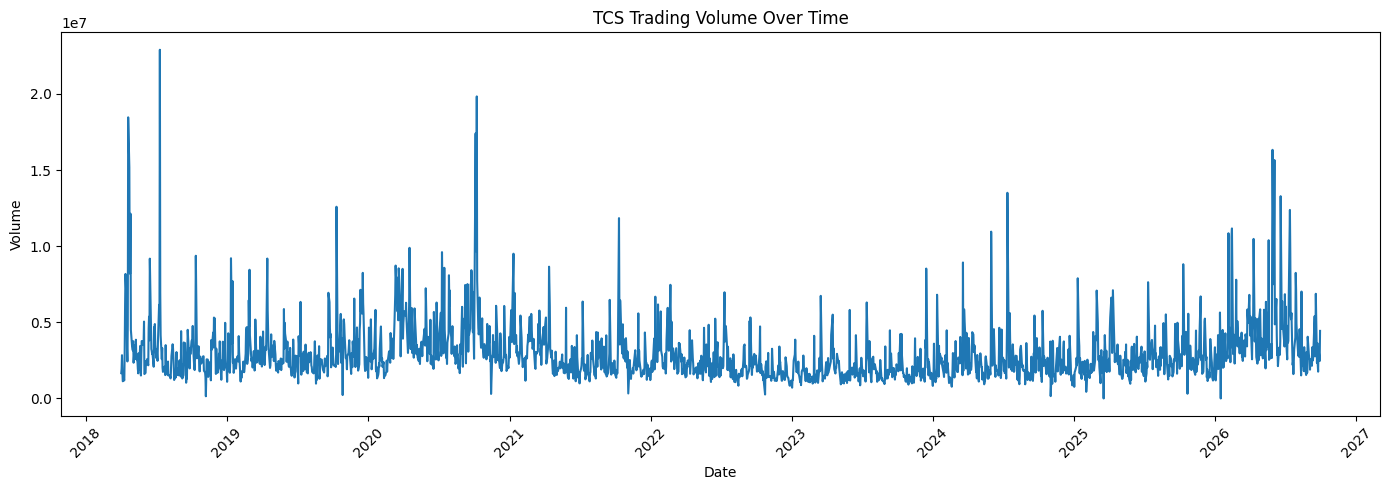

In [140]:
plt.figure(figsize=(14, 5))

plt.plot(
    df["Date"],
    df["Volume"]
)

plt.title("TCS Trading Volume Over Time")
plt.xlabel("Date")
plt.ylabel("Volume")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

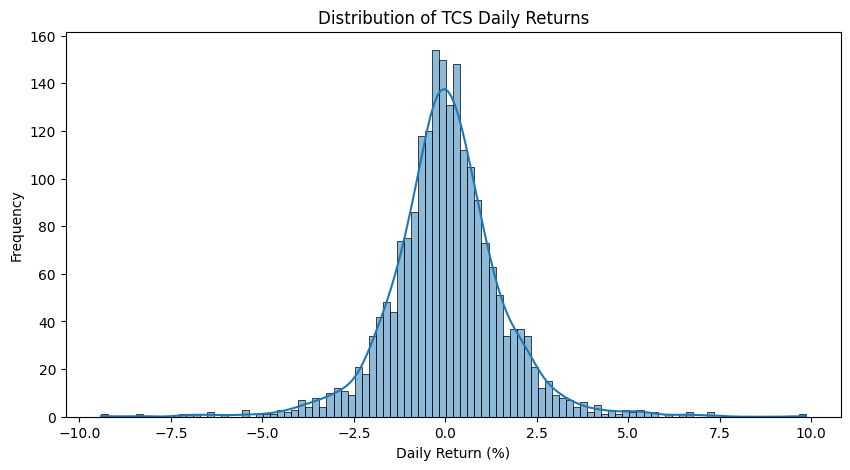

In [141]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["Daily_Return"],
    bins=100,
    kde=True
)

plt.title("Distribution of TCS Daily Returns")
plt.xlabel("Daily Return (%)")
plt.ylabel("Frequency")

plt.show()

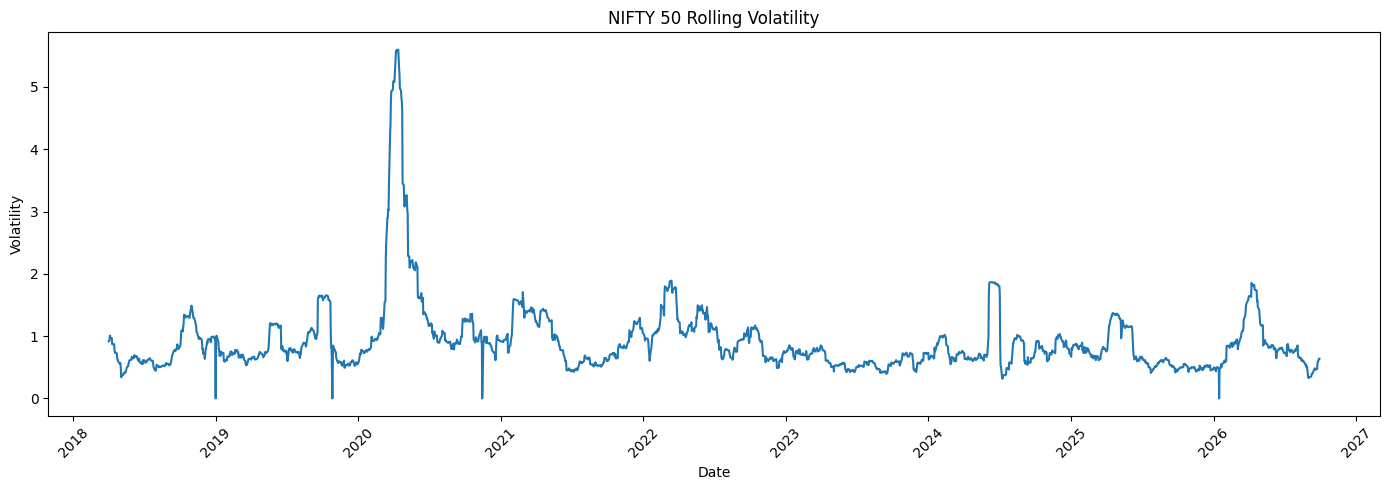

In [142]:
plt.figure(figsize=(14, 5))

plt.plot(
    df["Date"],
    df["NIFTY_Volatility"]
)

plt.title("NIFTY 50 Rolling Volatility")
plt.xlabel("Date")
plt.ylabel("Volatility")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

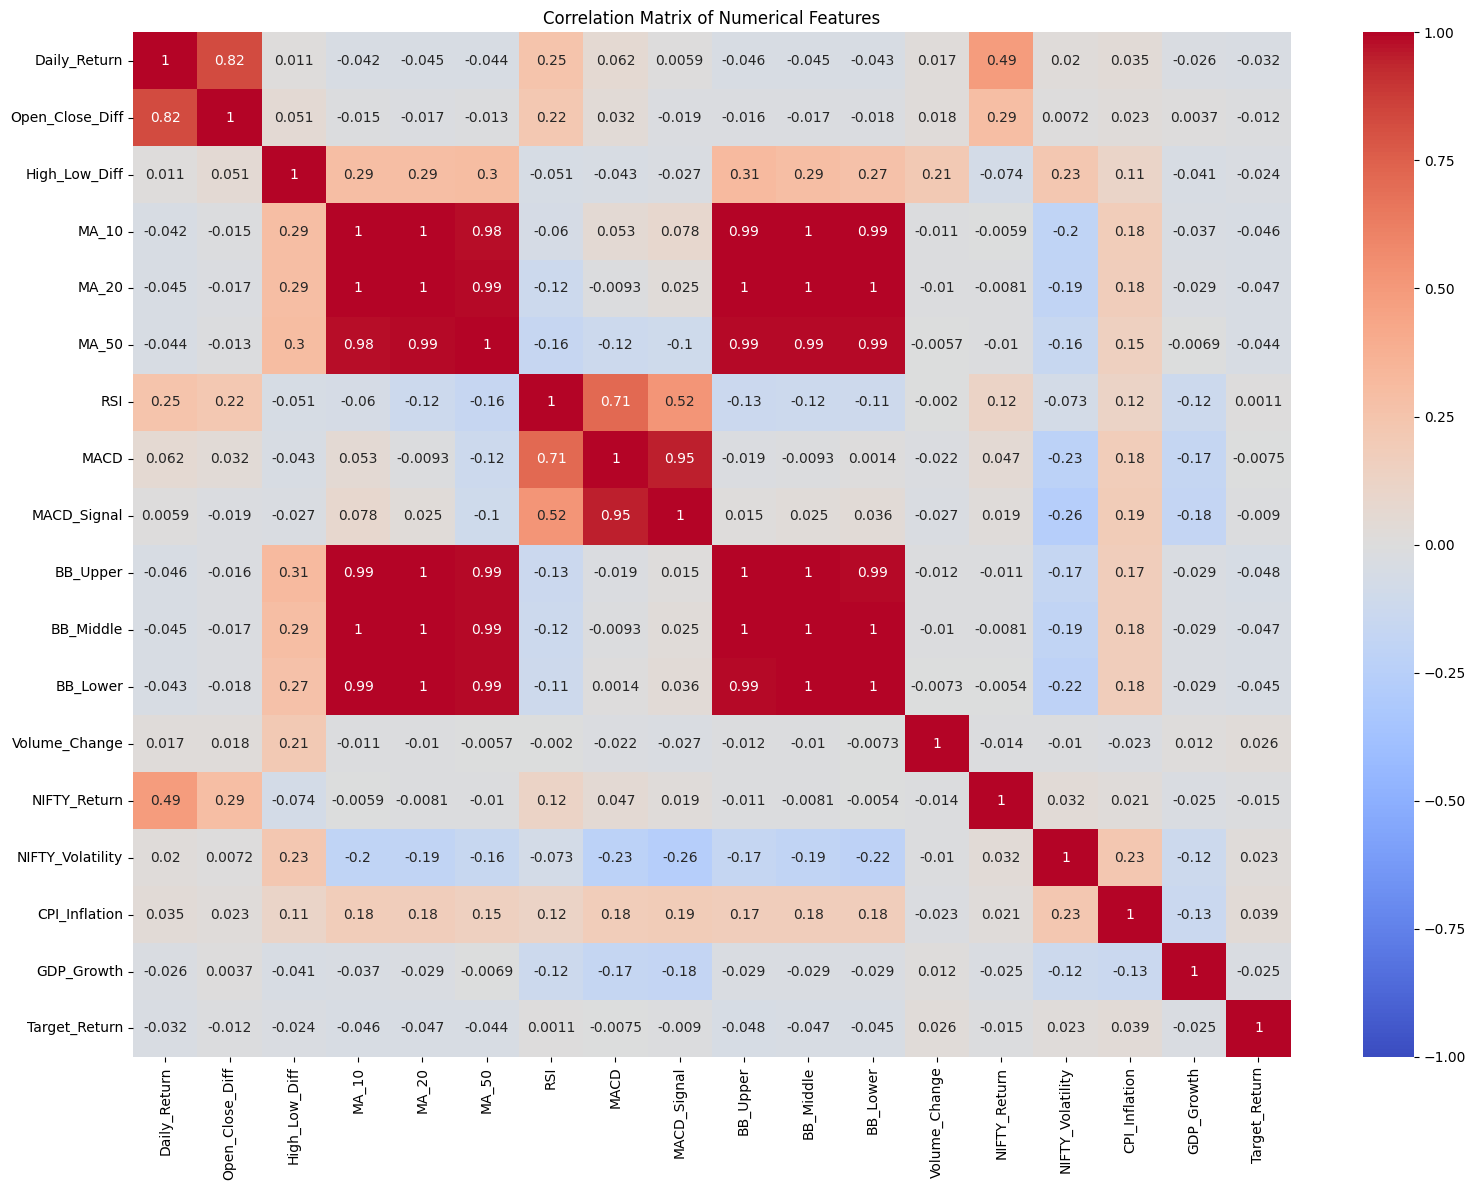

In [143]:
corr_cols = [
    "Daily_Return",
    "Open_Close_Diff",
    "High_Low_Diff",
    "MA_10",
    "MA_20",
    "MA_50",
    "RSI",
    "MACD",
    "MACD_Signal",
    "BB_Upper",
    "BB_Middle",
    "BB_Lower",
    "Volume_Change",
    "NIFTY_Return",
    "NIFTY_Volatility",
    "CPI_Inflation",
    "GDP_Growth",
    "Target_Return"
]

corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(16, 12))

sns.heatmap(
    corr_matrix,
    annot=True,
    vmin=-1,
    vmax=1,
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()

plt.show()

In [144]:
df.columns

Index(['Date', 'Open', 'High', 'Low', 'Close', 'Volume', 'Daily_Return',
       'Open_Close_Diff', 'High_Low_Diff', 'MA_10', 'MA_20', 'MA_50', 'RSI',
       'MACD', 'MACD_Signal', 'BB_Upper', 'BB_Middle', 'BB_Lower',
       'Volume_Change', 'Volume_MA', 'Close_Lag_1', 'Close_Lag_5',
       'Close_Lag_10', 'Close_Lag_20', 'NIFTY_Close', 'NIFTY_Return',
       'NIFTY_Volatility', 'CPI_Inflation', 'GDP_Growth', 'Target_Price',
       'Target_Return', 'Target_Class'],
      dtype='object')

**Technical Indicator Visualization**

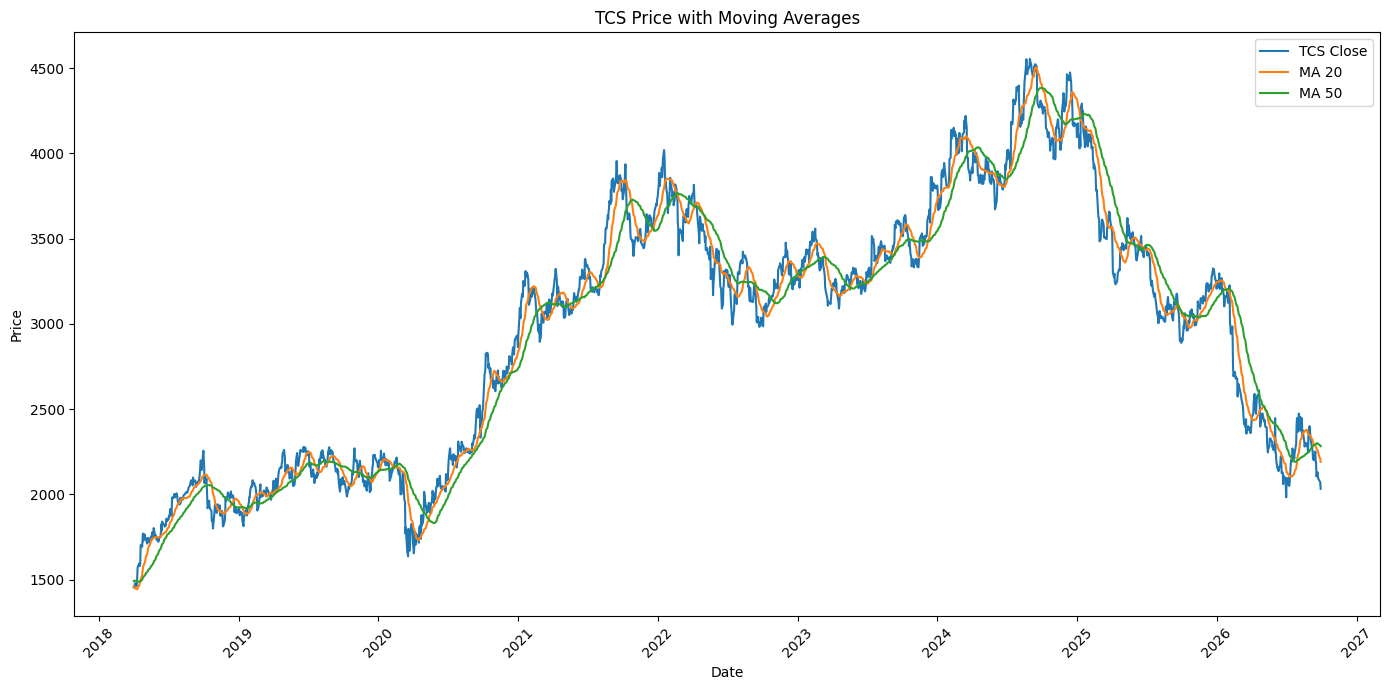

In [145]:
plt.figure(figsize=(14, 7))

plt.plot(
    df["Date"],
    df["Close"],
    label="TCS Close"
)

plt.plot(
    df["Date"],
    df["MA_20"],
    label="MA 20"
)

plt.plot(
    df["Date"],
    df["MA_50"],
    label="MA 50"
)

plt.title("TCS Price with Moving Averages")
plt.xlabel("Date")
plt.ylabel("Price")

plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

**RSI**

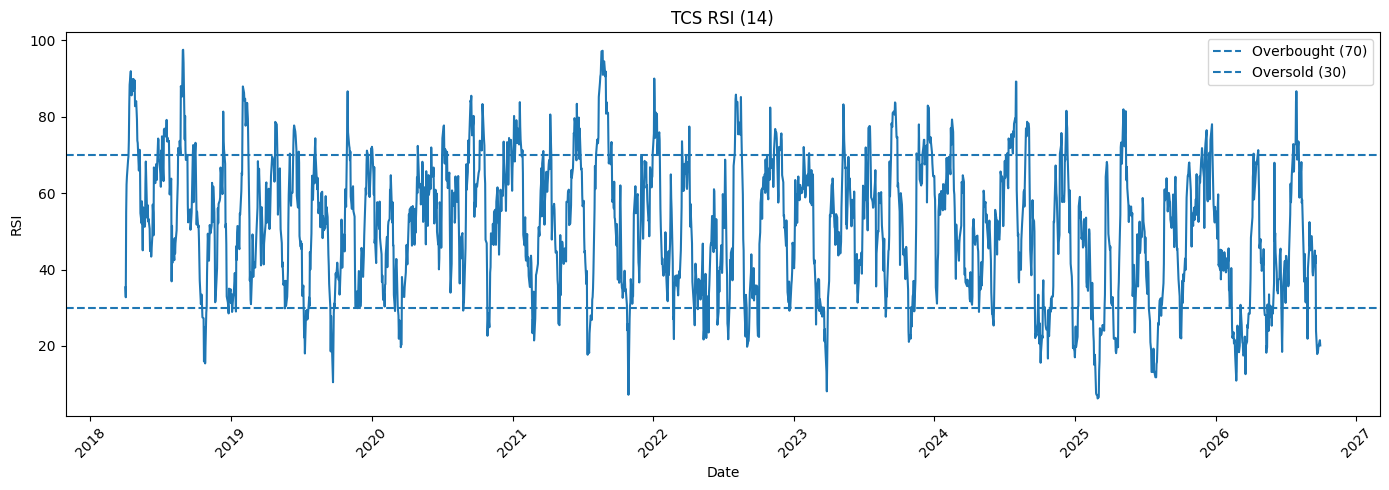

In [146]:
plt.figure(figsize=(14, 5))

plt.plot(
    df["Date"],
    df["RSI"]
)

plt.axhline(
    70,
    linestyle="--",
    label="Overbought (70)"
)

plt.axhline(
    30,
    linestyle="--",
    label="Oversold (30)"
)

plt.title("TCS RSI (14)")
plt.xlabel("Date")
plt.ylabel("RSI")

plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

**MACD**

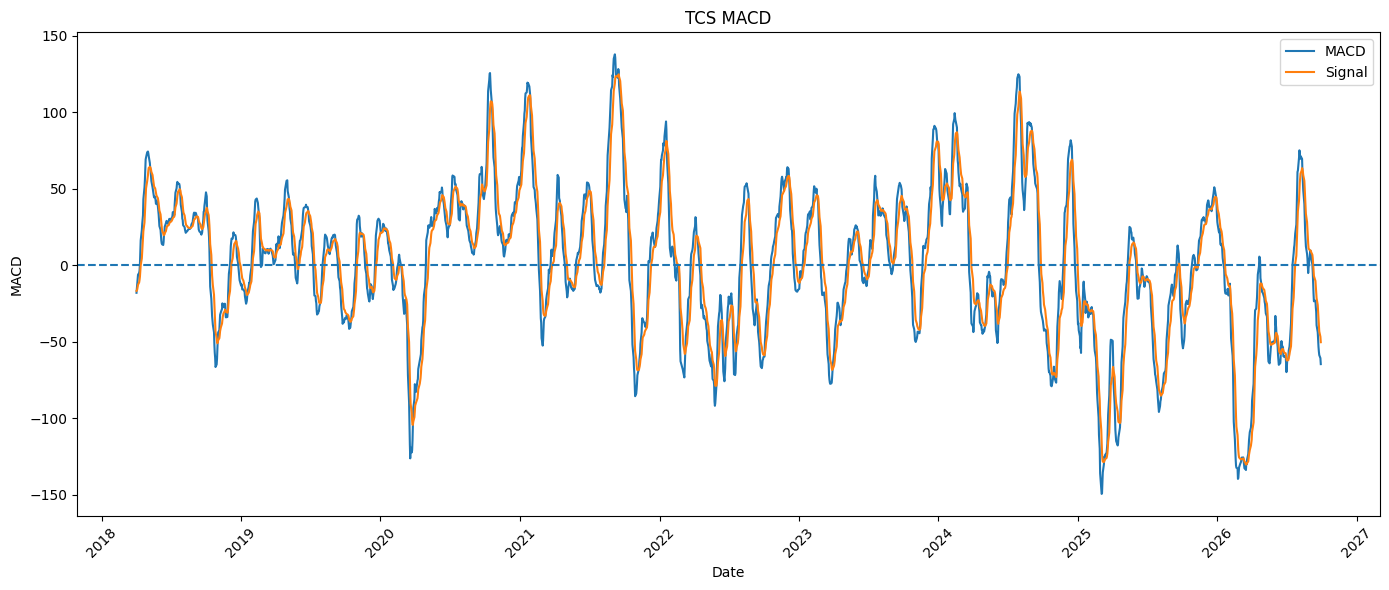

In [147]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["Date"],
    df["MACD"],
    label="MACD"
)

plt.plot(
    df["Date"],
    df["MACD_Signal"],
    label="Signal"
)

plt.axhline(
    0,
    linestyle="--"
)

plt.title("TCS MACD")
plt.xlabel("Date")
plt.ylabel("MACD")

plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

**FEATURE Engineering**

In [148]:
target = "Target_Class"

y = df[target].copy()

print("Target shape:", y.shape)
print("\nTarget classes:")
print(y.value_counts())

Target shape: (2100,)

Target classes:
Target_Class
HOLD    1247
BUY      436
SELL     417
Name: count, dtype: int64


In [149]:
leakage_columns = [
    "Target_Price",
    "Target_Return",
    "Target_Class"
]

X = df.drop(columns=leakage_columns).copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (2100, 29)
y shape: (2100,)


In [150]:
dates = X["Date"].copy()

X = X.drop(columns=["Date"])

print("Features:", X.shape[1])

Features: 28


In [151]:
print("Numerical features:")
print(X.select_dtypes(include=np.number).columns.tolist())

print("\nCategorical features:")
print(X.select_dtypes(exclude=np.number).columns.tolist())

Numerical features:
['Open', 'High', 'Low', 'Close', 'Volume', 'Daily_Return', 'Open_Close_Diff', 'High_Low_Diff', 'MA_10', 'MA_20', 'MA_50', 'RSI', 'MACD', 'MACD_Signal', 'BB_Upper', 'BB_Middle', 'BB_Lower', 'Volume_Change', 'Volume_MA', 'Close_Lag_1', 'Close_Lag_5', 'Close_Lag_10', 'Close_Lag_20', 'NIFTY_Close', 'NIFTY_Return', 'NIFTY_Volatility', 'CPI_Inflation', 'GDP_Growth']

Categorical features:
[]


In [152]:
price_features = [
    "Open",
    "High",
    "Low",
    "Close",
    "Volume"
]

return_features = [
    "Daily_Return",
    "Open_Close_Diff",
    "High_Low_Diff"
]

technical_features = [
    "MA_10",
    "MA_20",
    "MA_50",
    "RSI",
    "MACD",
    "MACD_Signal",
    "BB_Upper",
    "BB_Middle",
    "BB_Lower",
    "Volume_Change",
    "Volume_MA"
]

lag_features = [
    "Close_Lag_1",
    "Close_Lag_5",
    "Close_Lag_10",
    "Close_Lag_20"
]

market_features = [
    "NIFTY_Close",
    "NIFTY_Return",
    "NIFTY_Volatility"
]

macro_features = [
    "USD_INR",
    "CPI_Inflation",
    "GDP_Growth"
]

In [153]:
feature_columns = (
    price_features
    + return_features
    + technical_features
    + lag_features
    + market_features
    + macro_features
)

print("Total selected features:", len(feature_columns))
print(feature_columns)

Total selected features: 29
['Open', 'High', 'Low', 'Close', 'Volume', 'Daily_Return', 'Open_Close_Diff', 'High_Low_Diff', 'MA_10', 'MA_20', 'MA_50', 'RSI', 'MACD', 'MACD_Signal', 'BB_Upper', 'BB_Middle', 'BB_Lower', 'Volume_Change', 'Volume_MA', 'Close_Lag_1', 'Close_Lag_5', 'Close_Lag_10', 'Close_Lag_20', 'NIFTY_Close', 'NIFTY_Return', 'NIFTY_Volatility', 'USD_INR', 'CPI_Inflation', 'GDP_Growth']


In [154]:
inf_count = np.isinf(X.select_dtypes(include=np.number)).sum().sum()

print("Infinite values:", inf_count)

Infinite values: 2


In [155]:
X = X.replace([np.inf, -np.inf], np.nan)

In [156]:
print("Missing values after replacing infinity:")
print(X.isna().sum().sort_values(ascending=False).head(20))

Missing values after replacing infinity:
Volume_Change      2
Open               0
Low                0
High               0
Volume             0
Daily_Return       0
Open_Close_Diff    0
High_Low_Diff      0
MA_10              0
MA_20              0
MA_50              0
Close              0
RSI                0
MACD               0
BB_Upper           0
MACD_Signal        0
BB_Middle          0
BB_Lower           0
Volume_MA          0
Close_Lag_1        0
dtype: int64


In [157]:
skewness = (
    X.select_dtypes(include=np.number)
    .skew()
    .sort_values(ascending=False)
)

display(skewness.to_frame("Skewness"))

,Skewness
Volume_Change,11.529290
NIFTY_Volatility,4.415233
Volume,3.348033
High_Low_Diff,1.901818
Volume_MA,1.526752
Open_Close_Diff,0.205783
Daily_Return,0.045453
NIFTY_Close,0.016113
High,-0.050217
RSI,-0.054606


In [158]:
corr = X.corr()

upper = corr.where(
    np.triu(
        np.ones(corr.shape),
        k=1
    ).astype(bool)
)

high_corr = (
    upper.stack()
    .reset_index()
)

high_corr.columns = [
    "Feature_1",
    "Feature_2",
    "Correlation"
]

high_corr = high_corr[
    high_corr["Correlation"].abs() >= 0.90
].sort_values(
    "Correlation",
    key=lambda x: x.abs(),
    ascending=False
)

display(high_corr)

,Feature_1,Feature_2,Correlation
212,MA_20,BB_Middle,1.000000
18,Open,Close_Lag_1,0.999539
28,High,Close,0.999492
53,Low,Close,0.999439
1,Open,Low,0.999406
...,...,...,...
47,High,Close_Lag_20,0.969123
21,Open,Close_Lag_20,0.969044
72,Low,Close_Lag_20,0.968380
96,Close,Close_Lag_20,0.968024


In [159]:
from sklearn.ensemble import RandomForestClassifier

split_index = int(len(X) * 0.80)

X_temp = X.iloc[:split_index].copy()
y_temp = y.iloc[:split_index].copy()

print("Training portion:", X_temp.shape)

Training portion: (1680, 28)


In [160]:
X_temp = X_temp.replace([np.inf, -np.inf], np.nan)

X_temp = X_temp.dropna()
y_temp = y.loc[X_temp.index]

print(X_temp.shape)

(1680, 28)


In [161]:
rf_eda = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

rf_eda.fit(X_temp, y_temp)

RandomForestClassifier(class_weight='balanced', n_estimators=300, n_jobs=-1,
                       random_state=42)

In [162]:
importance_df = pd.DataFrame({
    "Feature": X_temp.columns,
    "Importance": rf_eda.feature_importances_
}).sort_values(
    "Importance",
    ascending=False
)

display(importance_df)

,Feature,Importance
24,NIFTY_Return,0.053059
4,Volume,0.048603
11,RSI,0.048466
17,Volume_Change,0.048140
5,Daily_Return,0.047143
7,High_Low_Diff,0.046722
25,NIFTY_Volatility,0.044757
13,MACD_Signal,0.043333
12,MACD,0.043068
6,Open_Close_Diff,0.042803


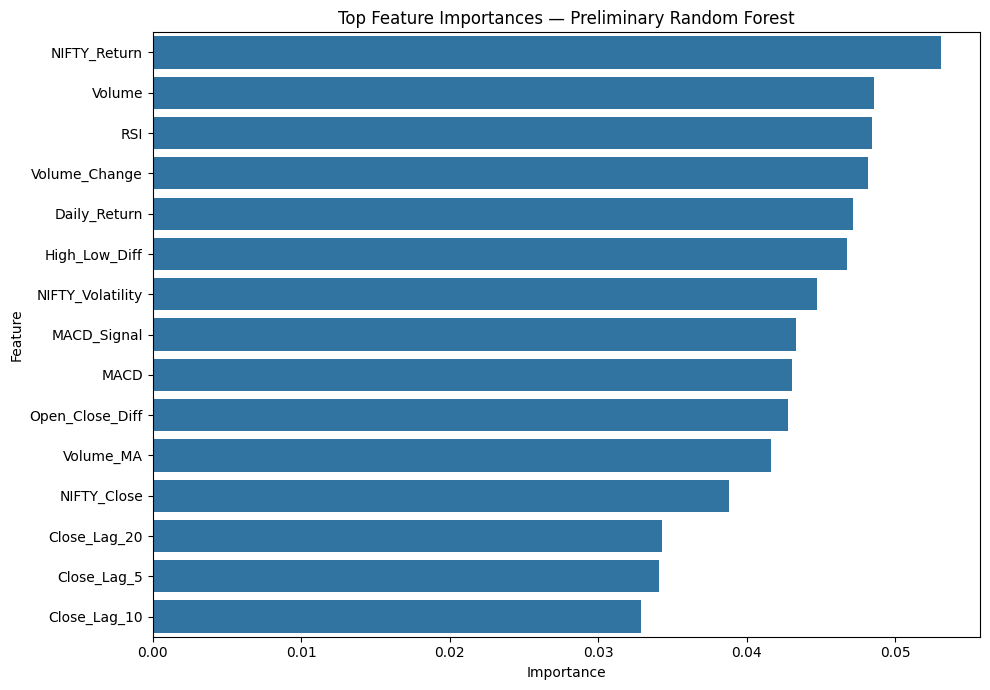

In [163]:
top_n = 15

plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df.head(top_n),
    x="Importance",
    y="Feature"
)

plt.title("Top Feature Importances — Preliminary Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [164]:
X = X.replace([np.inf, -np.inf], np.nan)

valid_mask = X.notna().all(axis=1) & y.notna()

X = X.loc[valid_mask].reset_index(drop=True)
y = y.loc[valid_mask].reset_index(drop=True)
dates = dates.loc[valid_mask].reset_index(drop=True)

print("Final usable samples:", len(X))

Final usable samples: 2098


In [165]:
print("Missing X:", X.isna().sum().sum())
print("Missing y:", y.isna().sum())

Missing X: 0
Missing y: 0


In [166]:
sort_idx = dates.argsort()

X = X.iloc[sort_idx].reset_index(drop=True)
y = y.iloc[sort_idx].reset_index(drop=True)
dates = dates.iloc[sort_idx].reset_index(drop=True)

print("Start:", dates.iloc[0])
print("End:", dates.iloc[-1])

Start: 2018-04-02 00:00:00
End: 2026-09-29 00:00:00


In [167]:
n = len(X)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

print("Total:", n)
print("Train:", train_end)
print("Validation:", val_end - train_end)
print("Test:", n - val_end)

Total: 2098
Train: 1468
Validation: 315
Test: 315


In [168]:
X_train = X.iloc[:train_end].copy()
X_val = X.iloc[train_end:val_end].copy()
X_test = X.iloc[val_end:].copy()

y_train = y.iloc[:train_end].copy()
y_val = y.iloc[train_end:val_end].copy()
y_test = y.iloc[val_end:].copy()

date_train = dates.iloc[:train_end].copy()
date_val = dates.iloc[train_end:val_end].copy()
date_test = dates.iloc[val_end:].copy()

In [169]:
print("TRAIN")
print(X_train.shape)
print(date_train.min(), "→", date_train.max())

print("\nVALIDATION")
print(X_val.shape)
print(date_val.min(), "→", date_val.max())

print("\nTEST")
print(X_test.shape)
print(date_test.min(), "→", date_test.max())

TRAIN
(1468, 28)
2018-04-02 00:00:00 → 2024-03-07 00:00:00

VALIDATION
(315, 28)
2024-03-11 00:00:00 → 2025-06-20 00:00:00

TEST
(315, 28)
2025-06-23 00:00:00 → 2026-09-29 00:00:00


In [170]:
print(
    "Train ends:",
    date_train.max()
)

print(
    "Validation starts:",
    date_val.min()
)

print(
    "Validation ends:",
    date_val.max()
)

print(
    "Test starts:",
    date_test.min()
)

Train ends: 2024-03-07 00:00:00
Validation starts: 2024-03-11 00:00:00
Validation ends: 2025-06-20 00:00:00
Test starts: 2025-06-23 00:00:00


In [171]:
def class_distribution(y_data, name):
    result = pd.DataFrame({
        "Count": y_data.value_counts(),
        "Percentage": (
            y_data.value_counts(normalize=True) * 100
        ).round(2)
    })

    print(f"\n{name}")
    display(result)

class_distribution(y_train, "TRAIN")
class_distribution(y_val, "VALIDATION")
class_distribution(y_test, "TEST")


TRAIN


,Count,Percentage
Target_Class,,
HOLD,859,58.51
BUY,327,22.28
SELL,282,19.21



VALIDATION


,Count,Percentage
Target_Class,,
HOLD,202,64.13
SELL,65,20.63
BUY,48,15.24



TEST


,Count,Percentage
Target_Class,,
HOLD,186,59.05
SELL,69,21.90
BUY,60,19.05


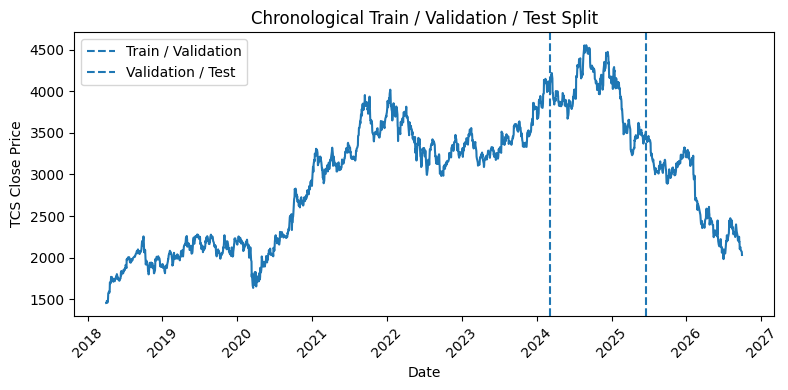

In [172]:
plt.figure(figsize=(8, 4))

plt.plot(
    dates,
    df.loc[valid_mask, "Close"].values
)

plt.axvline(
    date_train.max(),
    linestyle="--",
    label="Train / Validation"
)

plt.axvline(
    date_val.max(),
    linestyle="--",
    label="Validation / Test"
)

plt.title("Chronological Train / Validation / Test Split")
plt.xlabel("Date")
plt.ylabel("TCS Close Price")

plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [173]:
print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

print("\nTrain period:")
print(date_train.min(), "→", date_train.max())

print("\nValidation period:")
print(date_val.min(), "→", date_val.max())

print("\nTest period:")
print(date_test.min(), "→", date_test.max())

Train: (1468, 28) (1468,)
Validation: (315, 28) (315,)
Test: (315, 28) (315,)

Train period:
2018-04-02 00:00:00 → 2024-03-07 00:00:00

Validation period:
2024-03-11 00:00:00 → 2025-06-20 00:00:00

Test period:
2025-06-23 00:00:00 → 2026-09-29 00:00:00


**Baseline model**

In [175]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_val_encoded = label_encoder.transform(y_val)
y_test_encoded = label_encoder.transform(y_test)

print(label_encoder.classes_)


['BUY' 'HOLD' 'SELL']


In [176]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Calculate class weights using training data only
classes = np.unique(y_train_encoded)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_encoded
)

class_weight_dict = dict(zip(classes, weights))

print("Class Weights:")

for cls, weight in class_weight_dict.items():
    class_name = label_encoder.inverse_transform([cls])[0]
    print(f"{class_name}: {weight:.4f}")

Class Weights:
BUY: 1.4964
HOLD: 0.5697
SELL: 1.7352


In [177]:
sample_weights = np.array([
    class_weight_dict[label]
    for label in y_train_encoded
])

print("Sample weights shape:", sample_weights.shape)
print("Training target shape:", y_train_encoded.shape)

Sample weights shape: (1468,)
Training target shape: (1468,)


In [178]:
logistic_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])
logistic_pipeline

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=2000,
                                    random_state=42))])

In [179]:
logistic_pipeline.fit(
    X_train,
    y_train_encoded
)
logistic_val_pred = logistic_pipeline.predict(X_val)

logistic_val_proba = logistic_pipeline.predict_proba(X_val)

print("Predictions:", logistic_val_pred[:10])
print("Probabilities:")
print(logistic_val_proba[:5])

Predictions: [2 1 2 2 2 1 0 1 1 0]
Probabilities:
[[0.23577195 0.37104854 0.39317951]
 [0.26713535 0.37917172 0.35369293]
 [0.21116018 0.33977194 0.44906788]
 [0.2602543  0.36592299 0.3738227 ]
 [0.23236081 0.3680329  0.39960629]]


In [180]:
xgb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", XGBClassifier(
        objective="multi:softprob",
        num_class=3,
        eval_metric="mlogloss",
        random_state=42,
        n_jobs=-1
    ))
])
xgb_pipeline

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('classifier',
                 XGBClassifier(base_score=None, booster=None, callbacks=None,
                               colsample_bylevel=None, colsample_bynode=None,
                               colsample_bytree=None, device=None,
                               early_stopping_rounds=None,
                               enable_categorical=True, eval_metric='mlogloss',
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=None,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=None, n_jobs=-1, num_class=3, ...))])

In [181]:
xgb_pipeline.fit(
    X_train,
    y_train_encoded,
    classifier__sample_weight=sample_weights
)

xgb_val_pred = xgb_pipeline.predict(X_val)

xgb_val_proba = xgb_pipeline.predict_proba(X_val)

print("Predictions:", xgb_val_pred[:10])

print("\nProbabilities:")
print(xgb_val_proba[:5])

Predictions: [1 1 1 1 1 1 0 0 0 0]

Probabilities:
[[0.28864613 0.6955432  0.01581063]
 [0.19923408 0.7666268  0.03413911]
 [0.0472822  0.8808637  0.07185408]
 [0.04305083 0.9022301  0.05471903]
 [0.01631811 0.9496726  0.03400936]]


**SVM**

In [182]:
from sklearn.svm import SVC

svm_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        probability=True,
        class_weight="balanced",
        random_state=42
    ))
])

svm_pipeline

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('classifier',
                 SVC(class_weight='balanced', probability=True,
                     random_state=42))])

In [183]:
svm_pipeline.fit(
    X_train,
    y_train_encoded
)

svm_val_pred = svm_pipeline.predict(X_val)

svm_val_proba = svm_pipeline.predict_proba(X_val)

print("Predictions:")
print(svm_val_pred[:10])

print("\nProbability shape:")
print(svm_val_proba.shape)

Predictions:
[2 1 2 2 2 2 0 2 2 0]

Probability shape:
(315, 3)


**Evaluation function**

In [186]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

def evaluate_model(y_true, y_pred, model_name):

    print("=" * 60)
    print(model_name)
    print("=" * 60)

    print(
        f"Accuracy : "
        f"{accuracy_score(y_true, y_pred):.4f}"
    )

    print(
        f"Precision: "
        f"{precision_score(y_true, y_pred, average='macro'):.4f}"
    )

    print(
        f"Recall   : "
        f"{recall_score(y_true, y_pred, average='macro'):.4f}"
    )

    print(
        f"F1 Macro : "
        f"{f1_score(y_true, y_pred, average='macro'):.4f}"
    )

    print("\nClassification Report:")

    print(
        classification_report(
            y_true,
            y_pred,
            target_names=label_encoder.classes_
        )
    )

In [187]:
evaluate_model(
    y_val_encoded,
    svm_val_pred,
    "SVM Baseline"
)

SVM Baseline
Accuracy : 0.3905
Precision: 0.2987
Recall   : 0.3179
F1 Macro : 0.2892

Classification Report:
              precision    recall  f1-score   support

         BUY       0.07      0.04      0.05        48
        HOLD       0.61      0.45      0.52       202
        SELL       0.22      0.46      0.30        65

    accuracy                           0.39       315
   macro avg       0.30      0.32      0.29       315
weighted avg       0.45      0.39      0.40       315



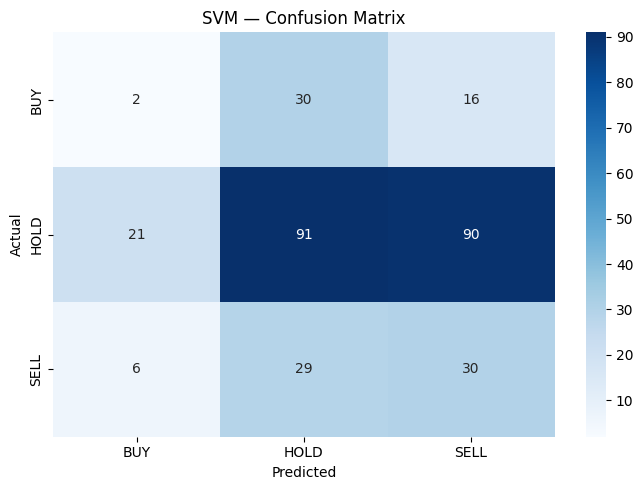

In [188]:
cm_svm = confusion_matrix(
    y_val_encoded,
    svm_val_pred
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("SVM — Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

In [189]:
prediction_distribution = pd.DataFrame({
    "Actual": pd.Series(y_val_encoded).value_counts(),
    "SVM_Predicted": pd.Series(svm_val_pred).value_counts()
})

prediction_distribution.index = label_encoder.inverse_transform(
    prediction_distribution.index
)

display(prediction_distribution)

,Actual,SVM_Predicted
HOLD,202,150
SELL,65,136
BUY,48,29


In [191]:
evaluate_model(
    y_val_encoded,
    logistic_val_pred,
    "Logistic Regression"
)


Logistic Regression
Accuracy : 0.4857
Precision: 0.3145
Recall   : 0.3155
F1 Macro : 0.3131

Classification Report:
              precision    recall  f1-score   support

         BUY       0.13      0.12      0.13        48
        HOLD       0.62      0.68      0.65       202
        SELL       0.19      0.14      0.16        65

    accuracy                           0.49       315
   macro avg       0.31      0.32      0.31       315
weighted avg       0.46      0.49      0.47       315



In [192]:

evaluate_model(
    y_val_encoded,
    xgb_val_pred,
    "XGBoost"
)

XGBoost
Accuracy : 0.5238
Precision: 0.2836
Recall   : 0.3464
F1 Macro : 0.3110

Classification Report:
              precision    recall  f1-score   support

         BUY       0.20      0.29      0.24        48
        HOLD       0.65      0.75      0.70       202
        SELL       0.00      0.00      0.00        65

    accuracy                           0.52       315
   macro avg       0.28      0.35      0.31       315
weighted avg       0.45      0.52      0.48       315



In [196]:
comparison = pd.DataFrame({

    "Model": [
        "Logistic Regression",
        "XGBoost",
        "SVM"
    ],

    "Accuracy": [
        accuracy_score(
            y_val_encoded,
            logistic_val_pred
        ),
        accuracy_score(
            y_val_encoded,
            xgb_val_pred
        ),
        accuracy_score(
            y_val_encoded,
            svm_val_pred
        )
    ],

    "Precision_Macro": [
        precision_score(
            y_val_encoded,
            logistic_val_pred,
            average="macro"
        ),
        precision_score(
            y_val_encoded,
            xgb_val_pred,
            average="macro"
        ),
        precision_score(
            y_val_encoded,
            svm_val_pred,
            average="macro"
        )
    ],

    "Recall_Macro": [
        recall_score(
            y_val_encoded,
            logistic_val_pred,
            average="macro"
        ),
        recall_score(
            y_val_encoded,
            xgb_val_pred,
            average="macro"
        ),
        recall_score(
            y_val_encoded,
            svm_val_pred,
            average="macro"
        )
    ],

    "F1_Macro": [
        f1_score(
            y_val_encoded,
            logistic_val_pred,
            average="macro"
        ),
        f1_score(
            y_val_encoded,
            xgb_val_pred,
            average="macro"
        ),
        f1_score(
            y_val_encoded,
            svm_val_pred,
            average="macro"
        )
    ]
})

comparison = comparison.sort_values(
    "F1_Macro",
    ascending=False
).reset_index(drop=True)

display(comparison)

,Model,Accuracy,Precision_Macro,Recall_Macro,F1_Macro
0,Logistic Regression,0.485714,0.314515,0.315543,0.313106
1,XGBoost,0.523810,0.283621,0.346397,0.311047
2,SVM,0.390476,0.298740,0.317900,0.289167


**Cross-Validation + Hyperparameter Tuning**

In [194]:
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
tscv = TimeSeriesSplit(n_splits=5)

print(tscv)

TimeSeriesSplit(gap=0, max_train_size=None, n_splits=5, test_size=None)


In [197]:
logistic_params = {
    "classifier__C": [
        0.001,
        0.01,
        0.1,
        1,
        10,
        100
    ],

    "classifier__penalty": [
        "l1",
        "l2"
    ],

    "classifier__solver": [
        "liblinear"
    ],

    "classifier__class_weight": [
        None,
        "balanced"
    ]
}

**RandomizedSearchCV for Logistic Regression**

In [198]:
logistic_search = RandomizedSearchCV(
    estimator=logistic_pipeline,
    param_distributions=logistic_params,
    n_iter=20,
    scoring="f1_macro",
    cv=tscv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

In [199]:
logistic_search.fit(
    X_train,
    y_train_encoded
)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


RandomizedSearchCV(cv=TimeSeriesSplit(gap=0, max_train_size=None, n_splits=5, test_size=None),
                   estimator=Pipeline(steps=[('imputer',
                                              SimpleImputer(strategy='median')),
                                             ('scaler', StandardScaler()),
                                             ('classifier',
                                              LogisticRegression(class_weight='balanced',
                                                                 max_iter=2000,
                                                                 random_state=42))]),
                   n_iter=20, n_jobs=-1,
                   param_distributions={'classifier__C': [0.001, 0.01, 0.1, 1,
                                                          10, 100],
                                        'classifier__class_weight': [None,
                                                                     'balanced'],
                                        'classifier__penalty': ['l1', 'l2'],
                                        'classifier__solver': ['liblinear']},
                   random_state=42, return_train_score=True, scoring='f1_macro',
                   verbose=1)

In [200]:
print("Best Logistic Parameters:")
print(logistic_search.best_params_)

print("\nBest CV Macro F1:")
print(logistic_search.best_score_)

Best Logistic Parameters:
{'classifier__solver': 'liblinear', 'classifier__penalty': 'l2', 'classifier__class_weight': 'balanced', 'classifier__C': 0.01}

Best CV Macro F1:
0.2756806746694163


In [201]:
best_logistic = logistic_search.best_estimator_

logistic_tuned_val_pred = best_logistic.predict(X_val)

logistic_tuned_val_proba = (
    best_logistic.predict_proba(X_val)
)

In [202]:
evaluate_model(
    y_val_encoded,
    logistic_tuned_val_pred,
    "Tuned Logistic Regression"
)

Tuned Logistic Regression
Accuracy : 0.6159
Precision: 0.2113
Recall   : 0.3201
F1 Macro : 0.2546

Classification Report:
              precision    recall  f1-score   support

         BUY       0.00      0.00      0.00        48
        HOLD       0.63      0.96      0.76       202
        SELL       0.00      0.00      0.00        65

    accuracy                           0.62       315
   macro avg       0.21      0.32      0.25       315
weighted avg       0.41      0.62      0.49       315



**XGBoost Hyperparameter Tuning**

In [203]:
xgb_params = {
    "classifier__n_estimators": [
        100,
        200,
        300
    ],

    "classifier__max_depth": [
        3,
        4,
        5,
        6
    ],

    "classifier__learning_rate": [
        0.01,
        0.03,
        0.05,
        0.1
    ],

    "classifier__subsample": [
        0.7,
        0.8,
        0.9
    ],

    "classifier__colsample_bytree": [
        0.7,
        0.8,
        0.9
    ],

    "classifier__min_child_weight": [
        1,
        3,
        5
    ],

    "classifier__gamma": [
        0.1,
        0.3,
        0.5
    ],

    "classifier__reg_alpha": [
        0.01,
        0.1,
        1
    ],

    "classifier__reg_lambda": [
        1,
        2,
        5
    ]
}

In [204]:
xgb_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=xgb_params,
    n_iter=30,
    scoring="f1_macro",
    cv=tscv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

In [206]:
classifier__sample_weight=sample_weights

In [207]:
xgb_search.fit(
    X_train,
    y_train_encoded,
    classifier__sample_weight=sample_weights
)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


RandomizedSearchCV(cv=TimeSeriesSplit(gap=0, max_train_size=None, n_splits=5, test_size=None),
                   estimator=Pipeline(steps=[('imputer',
                                              SimpleImputer(strategy='median')),
                                             ('classifier',
                                              XGBClassifier(base_score=None,
                                                            booster=None,
                                                            callbacks=None,
                                                            colsample_bylevel=None,
                                                            colsample_bynode=None,
                                                            colsample_bytree=None,
                                                            device=None,
                                                            early_stopping_rounds=None,
                                                            enable_cat...
                                        'classifier__gamma': [0.1, 0.3, 0.5],
                                        'classifier__learning_rate': [0.01,
                                                                      0.03,
                                                                      0.05,
                                                                      0.1],
                                        'classifier__max_depth': [3, 4, 5, 6],
                                        'classifier__min_child_weight': [1, 3,
                                                                         5],
                                        'classifier__n_estimators': [100, 200,
                                                                     300],
                                        'classifier__reg_alpha': [0.01, 0.1, 1],
                                        'classifier__reg_lambda': [1, 2, 5],
                                        'classifier__subsample': [0.7, 0.8,
                                                                  0.9]},
                   random_state=42, return_train_score=True, scoring='f1_macro',
                   verbose=1)

In [208]:
print("Best XGBoost Parameters:")
print(xgb_search.best_params_)

print("\nBest CV Macro F1:")
print(xgb_search.best_score_)

Best XGBoost Parameters:
{'classifier__subsample': 0.8, 'classifier__reg_lambda': 1, 'classifier__reg_alpha': 1, 'classifier__n_estimators': 300, 'classifier__min_child_weight': 3, 'classifier__max_depth': 5, 'classifier__learning_rate': 0.1, 'classifier__gamma': 0.1, 'classifier__colsample_bytree': 0.7}

Best CV Macro F1:
0.3294374561129328


In [210]:
best_xgb = xgb_search.best_estimator_

In [211]:
xgb_tuned_val_pred = best_xgb.predict(X_val)

xgb_tuned_val_proba = (
    best_xgb.predict_proba(X_val)
)

In [212]:
evaluate_model(
    y_val_encoded,
    xgb_tuned_val_pred,
    "Tuned XGBoost"
)

Tuned XGBoost
Accuracy : 0.5492
Precision: 0.2913
Recall   : 0.3189
F1 Macro : 0.2971

Classification Report:
              precision    recall  f1-score   support

         BUY       0.14      0.10      0.12        48
        HOLD       0.65      0.82      0.73       202
        SELL       0.08      0.03      0.04        65

    accuracy                           0.55       315
   macro avg       0.29      0.32      0.30       315
weighted avg       0.46      0.55      0.49       315



In [213]:
results = []

models_to_compare = {
    "Logistic Baseline": (
        logistic_val_pred
    ),
    "Logistic Tuned": (
        logistic_tuned_val_pred
    ),
    "XGBoost Baseline": (
        xgb_val_pred
    ),
    "XGBoost Tuned": (
        xgb_tuned_val_pred
    )
}

for name, pred in models_to_compare.items():

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(
            y_val_encoded,
            pred
        ),
        "Precision_Macro": precision_score(
            y_val_encoded,
            pred,
            average="macro"
        ),
        "Recall_Macro": recall_score(
            y_val_encoded,
            pred,
            average="macro"
        ),
        "F1_Macro": f1_score(
            y_val_encoded,
            pred,
            average="macro"
        )
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    "F1_Macro",
    ascending=False
).reset_index(drop=True)

display(results_df)

,Model,Accuracy,Precision_Macro,Recall_Macro,F1_Macro
0,Logistic Baseline,0.485714,0.314515,0.315543,0.313106
1,XGBoost Baseline,0.523810,0.283621,0.346397,0.311047
2,XGBoost Tuned,0.549206,0.291279,0.318906,0.297134
3,Logistic Tuned,0.615873,0.211329,0.320132,0.254593


**SVM hyperparameter space**

In [214]:
svm_params = {
    "classifier__C": [
        0.01,
        0.1,
        1,
    ],

    "classifier__kernel": [
        "rbf",
        "linear"
    ],

    "classifier__gamma": [
        "auto",
        0.001,
        0.01
    ],

    "classifier__class_weight": [
        None,
        "balanced"
    ]
}

In [215]:
svm_search = RandomizedSearchCV(
    estimator=svm_pipeline,
    param_distributions=svm_params,
    n_iter=20,
    scoring="f1_macro",
    cv=tscv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

In [216]:
svm_search.fit(
    X_train,
    y_train_encoded
)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


RandomizedSearchCV(cv=TimeSeriesSplit(gap=0, max_train_size=None, n_splits=5, test_size=None),
                   estimator=Pipeline(steps=[('imputer',
                                              SimpleImputer(strategy='median')),
                                             ('scaler', StandardScaler()),
                                             ('classifier',
                                              SVC(class_weight='balanced',
                                                  probability=True,
                                                  random_state=42))]),
                   n_iter=20, n_jobs=-1,
                   param_distributions={'classifier__C': [0.01, 0.1, 1],
                                        'classifier__class_weight': [None,
                                                                     'balanced'],
                                        'classifier__gamma': ['auto', 0.001,
                                                              0.01],
                                        'classifier__kernel': ['rbf',
                                                               'linear']},
                   random_state=42, return_train_score=True, scoring='f1_macro',
                   verbose=1)

In [217]:
print("Best SVM Parameters:")
print(svm_search.best_params_)

print("\nBest CV Macro F1:")
print(svm_search.best_score_)

Best SVM Parameters:
{'classifier__kernel': 'linear', 'classifier__gamma': 'auto', 'classifier__class_weight': None, 'classifier__C': 0.1}

Best CV Macro F1:
0.2769806320375799


In [218]:
best_svm = svm_search.best_estimator_

svm_tuned_val_pred = best_svm.predict(X_val)

svm_tuned_val_proba = best_svm.predict_proba(X_val)

In [219]:
evaluate_model(
    y_val_encoded,
    svm_tuned_val_pred,
    "Tuned SVM"
)

Tuned SVM
Accuracy : 0.6413
Precision: 0.2138
Recall   : 0.3333
F1 Macro : 0.2605

Classification Report:
              precision    recall  f1-score   support

         BUY       0.00      0.00      0.00        48
        HOLD       0.64      1.00      0.78       202
        SELL       0.00      0.00      0.00        65

    accuracy                           0.64       315
   macro avg       0.21      0.33      0.26       315
weighted avg       0.41      0.64      0.50       315



In [220]:
results.append({
    "Model": "SVM Tuned",
    "Accuracy": accuracy_score(
        y_val_encoded,
        svm_tuned_val_pred
    ),
    "Precision_Macro": precision_score(
        y_val_encoded,
        svm_tuned_val_pred,
        average="macro"
    ),
    "Recall_Macro": recall_score(
        y_val_encoded,
        svm_tuned_val_pred,
        average="macro"
    ),
    "F1_Macro": f1_score(
        y_val_encoded,
        svm_tuned_val_pred,
        average="macro"
    )
})

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    "F1_Macro",
    ascending=False
).reset_index(drop=True)

display(results_df)

,Model,Accuracy,Precision_Macro,Recall_Macro,F1_Macro
0,Logistic Baseline,0.485714,0.314515,0.315543,0.313106
1,XGBoost Baseline,0.523810,0.283621,0.346397,0.311047
2,XGBoost Tuned,0.549206,0.291279,0.318906,0.297134
3,SVM Tuned,0.641270,0.213757,0.333333,0.260477
4,Logistic Tuned,0.615873,0.211329,0.320132,0.254593


In [221]:
prediction_check = pd.DataFrame({
    "Actual": pd.Series(y_val_encoded).value_counts(),

    "Logistic_Baseline": pd.Series(
        logistic_val_pred
    ).value_counts(),

    "Logistic_Tuned": pd.Series(
        logistic_tuned_val_pred
    ).value_counts(),

    "XGBoost_Baseline": pd.Series(
        xgb_val_pred
    ).value_counts(),

    "XGBoost_Tuned": pd.Series(
        xgb_tuned_val_pred
    ).value_counts(),

    "SVM_Baseline": pd.Series(
        svm_val_pred
    ).value_counts(),

    "SVM_Tuned": pd.Series(
        svm_tuned_val_pred
    ).value_counts()
}).fillna(0)

prediction_check.index = label_encoder.classes_

display(prediction_check)

,Actual,Logistic_Baseline,Logistic_Tuned,XGBoost_Baseline,XGBoost_Tuned,SVM_Baseline,SVM_Tuned
BUY,48,46,5,70,35,29,0.0
HOLD,202,222,306,232,255,150,315.0
SELL,65,47,4,13,25,136,0.0


In [222]:
print("Logistic CV F1:",
      logistic_search.best_score_)

print("XGBoost CV F1:",
      xgb_search.best_score_)

print("SVM CV F1:",
      svm_search.best_score_)

Logistic CV F1: 0.2756806746694163
XGBoost CV F1: 0.3294374561129328
SVM CV F1: 0.2769806320375799


In [223]:
print("\nValidation F1")

print(
    "Logistic:",
    f1_score(
        y_val_encoded,
        logistic_tuned_val_pred,
        average="macro"
    )
)

print(
    "XGBoost:",
    f1_score(
        y_val_encoded,
        xgb_tuned_val_pred,
        average="macro"
    )
)

print(
    "SVM:",
    f1_score(
        y_val_encoded,
        svm_tuned_val_pred,
        average="macro"
    )
)


Validation F1
Logistic: 0.2545931758530184
XGBoost: 0.2971344654084366
SVM: 0.26047711154094133


**Keep Logistic Regression Baseline as your current best model (Macro-F1 = 0.3300), and keep XGBoost as the strongest tuned candidate.**

**Threshold optimization model**

In [224]:
import numpy as np
from sklearn.metrics import f1_score


def optimize_multiclass_thresholds(
    y_true,
    probabilities,
    threshold_values=np.arange(0.50, 1.01, 0.05)
):
    """
    Optimize class-specific probability thresholds
    for a 3-class classification problem.

    Classes:
    0 = BUY
    1 = HOLD
    2 = SELL
    """

    best_score = -1
    best_thresholds = None
    best_predictions = None

    for t0 in threshold_values:
        for t1 in threshold_values:
            for t2 in threshold_values:

                thresholds = np.array([
                    t0, t1, t2
                ])

                # Adjust probabilities
                adjusted_probabilities = (
                    probabilities / thresholds
                )

                predictions = np.argmax(
                    adjusted_probabilities,
                    axis=1
                )

                score = f1_score(
                    y_true,
                    predictions,
                    average="macro"
                )

                if score > best_score:
                    best_score = score
                    best_thresholds = thresholds
                    best_predictions = predictions

    return (
        best_thresholds,
        best_score,
        best_predictions
    )



**Optimize Logistic Baseline**

In [228]:
logistic_thresholds, logistic_threshold_f1, logistic_threshold_pred = (
    optimize_multiclass_thresholds(
        y_val_encoded,
        logistic_val_proba
    )
)

print("Logistic Baseline")
print("Optimal thresholds:", logistic_thresholds)
print("Optimized Macro F1:", logistic_threshold_f1)

Logistic Baseline
Optimal thresholds: [0.85 1.   0.7 ]
Optimized Macro F1: 0.3791993865666992


**Optimize XGBoost**

In [225]:
xgb_thresholds, xgb_threshold_f1, xgb_threshold_pred = (
    optimize_multiclass_thresholds(
        y_val_encoded,
        xgb_tuned_val_proba
    )
)

print("XGBoost Tuned")
print("Optimal thresholds:", xgb_thresholds)
print("Optimized Macro F1:", xgb_threshold_f1)


XGBoost Tuned
Optimal thresholds: [0.95 0.95 0.5 ]
Optimized Macro F1: 0.31626758073698075


In [226]:
svm_thresholds, svm_threshold_f1, svm_threshold_pred = (
    optimize_multiclass_thresholds(
        y_val_encoded,
        svm_tuned_val_proba
    )
)

print("SVM Tuned")
print("Optimal thresholds:", svm_thresholds)
print("Optimized Macro F1:", svm_threshold_f1)

SVM Tuned
Optimal thresholds: [0.55 0.85 0.5 ]
Optimized Macro F1: 0.3069510711946861


In [229]:
threshold_comparison = pd.DataFrame({
    "Model": [
        "Logistic Baseline",
        "XGBoost Tuned",
        "SVM Tuned"
    ],

    "Default_Macro_F1": [
        f1_score(
            y_val_encoded,
            logistic_val_pred,
            average="macro"
        ),
        f1_score(
            y_val_encoded,
            xgb_tuned_val_pred,
            average="macro"
        ),
        f1_score(
            y_val_encoded,
            svm_tuned_val_pred,
            average="macro"
        )
    ],

    "Optimized_Macro_F1": [
        logistic_threshold_f1,
        xgb_threshold_f1,
        svm_threshold_f1
    ]
})

threshold_comparison["Improvement"] = (
    threshold_comparison["Optimized_Macro_F1"]
    -
    threshold_comparison["Default_Macro_F1"]
)

display(
    threshold_comparison.sort_values(
        "Optimized_Macro_F1",
        ascending=False
    )
)

,Model,Default_Macro_F1,Optimized_Macro_F1,Improvement
0,Logistic Baseline,0.313106,0.379199,0.066094
1,XGBoost Tuned,0.297134,0.316268,0.019133
2,SVM Tuned,0.260477,0.306951,0.046474


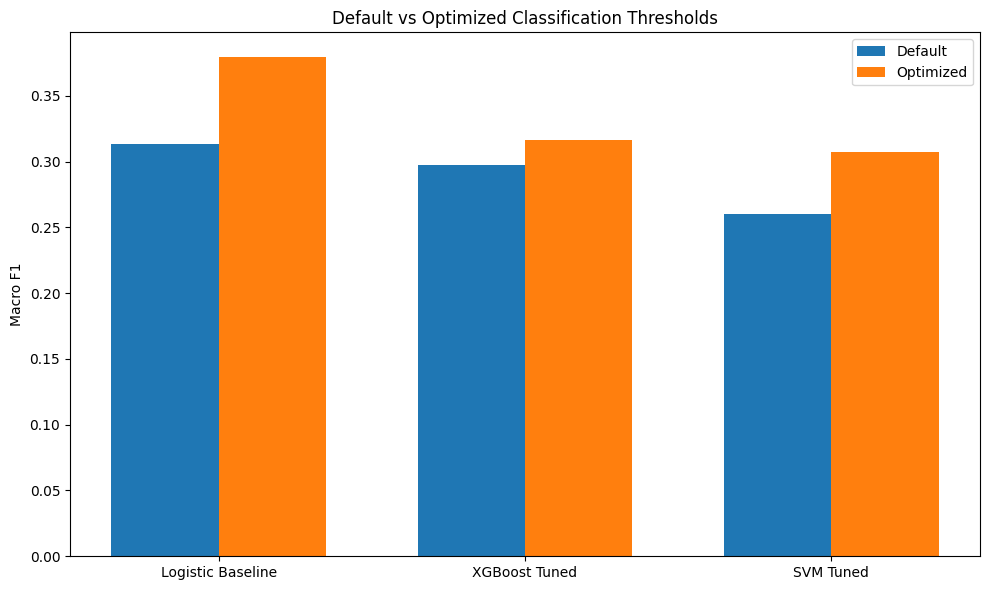

In [230]:
plt.figure(figsize=(10, 6))

x = np.arange(len(threshold_comparison))
width = 0.35

plt.bar(
    x - width / 2,
    threshold_comparison["Default_Macro_F1"],
    width,
    label="Default"
)

plt.bar(
    x + width / 2,
    threshold_comparison["Optimized_Macro_F1"],
    width,
    label="Optimized"
)

plt.xticks(
    x,
    threshold_comparison["Model"]
)

plt.ylabel("Macro F1")
plt.title("Default vs Optimized Classification Thresholds")

plt.legend()
plt.tight_layout()
plt.show()

In [231]:
evaluate_model(
    y_val_encoded,
    logistic_threshold_pred,
    "Logistic Baseline - Optimized Threshold"
)

Logistic Baseline - Optimized Threshold
Accuracy : 0.4254
Precision: 0.3895
Recall   : 0.4121
F1 Macro : 0.3792

Classification Report:
              precision    recall  f1-score   support

         BUY       0.23      0.40      0.29        48
        HOLD       0.68      0.44      0.54       202
        SELL       0.25      0.40      0.31        65

    accuracy                           0.43       315
   macro avg       0.39      0.41      0.38       315
weighted avg       0.53      0.43      0.45       315



In [232]:
evaluate_model(
    y_val_encoded,
    xgb_threshold_pred,
    "XGBoost Tuned - Optimized Threshold"
)

XGBoost Tuned - Optimized Threshold
Accuracy : 0.4730
Precision: 0.3200
Recall   : 0.3192
F1 Macro : 0.3163

Classification Report:
              precision    recall  f1-score   support

         BUY       0.14      0.08      0.10        48
        HOLD       0.64      0.64      0.64       202
        SELL       0.18      0.23      0.20        65

    accuracy                           0.47       315
   macro avg       0.32      0.32      0.32       315
weighted avg       0.47      0.47      0.47       315



**Probability Callibration**

In [233]:
cal_split = int(len(X_val) * 0.50)

X_cal = X_val.iloc[:cal_split].copy()
X_threshold = X_val.iloc[cal_split:].copy()

y_cal = y_val_encoded[:cal_split]
y_threshold = y_val_encoded[cal_split:]

print("Calibration set:", X_cal.shape)
print("Threshold set:", X_threshold.shape)

print("\nCalibration period:")
print(date_val.iloc[:cal_split].min(), "→",
      date_val.iloc[:cal_split].max())

print("\nThreshold period:")
print(date_val.iloc[cal_split:].min(), "→",
      date_val.iloc[cal_split:].max())

Calibration set: (157, 28)
Threshold set: (158, 28)

Calibration period:
2024-03-11 00:00:00 → 2024-10-29 00:00:00

Threshold period:
2024-10-30 00:00:00 → 2025-06-20 00:00:00


**Calibrated_logistic**

In [234]:
from sklearn.calibration import CalibratedClassifierCV
calibrated_logistic = CalibratedClassifierCV(
    estimator=best_logistic,
    method="sigmoid",
    cv="prefit"
)
calibrated_logistic.fit(
    X_cal,
    y_cal
)

CalibratedClassifierCV(cv='prefit',
                       estimator=Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler()),
                                                 ('classifier',
                                                  LogisticRegression(C=0.01,
                                                                     class_weight='balanced',
                                                                     max_iter=2000,
                                                                     random_state=42,
                                                                     solver='liblinear'))]))

In [235]:
from sklearn.frozen import FrozenEstimator

calibrated_logistic = CalibratedClassifierCV(
    estimator=FrozenEstimator(best_logistic),
    method="sigmoid"
)

calibrated_logistic.fit(
    X_cal,
    y_cal
)

CalibratedClassifierCV(estimator=FrozenEstimator(estimator=Pipeline(steps=[('imputer',
                                                                            SimpleImputer(strategy='median')),
                                                                           ('scaler',
                                                                            StandardScaler()),
                                                                           ('classifier',
                                                                            LogisticRegression(C=0.01,
                                                                                               class_weight='balanced',
                                                                                               max_iter=2000,
                                                                                               random_state=42,
                                                                                               solver='liblinear'))])))

**Calibrated_XGB**

In [236]:
calibrated_xgb = CalibratedClassifierCV(
    estimator=best_xgb,
    method="sigmoid",
    cv="prefit"
)

calibrated_xgb.fit(
    X_cal,
    y_cal
)

CalibratedClassifierCV(cv='prefit',
                       estimator=Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('classifier',
                                                  XGBClassifier(base_score=None,
                                                                booster=None,
                                                                callbacks=None,
                                                                colsample_bylevel=None,
                                                                colsample_bynode=None,
                                                                colsample_bytree=0.7,
                                                                device=None,
                                                                early_stopping_rounds=None,
                                                                enable_categorical=True,
                                                                eval_metric='mlogloss',
                                                                feature_types=None,
                                                                feature_weights=None,
                                                                gamma=0.1,
                                                                grow_policy=None,
                                                                importance_type=None,
                                                                interaction_constraints=None,
                                                                learning_rate=0.1,
                                                                max_bin=None,
                                                                max_cat_threshold=None,
                                                                max_cat_to_onehot=None,
                                                                max_delta_step=None,
                                                                max_depth=5,
                                                                max_leaves=None,
                                                                min_child_weight=3,
                                                                missing=nan,
                                                                monotone_constraints=None,
                                                                multi_strategy=None,
                                                                n_estimators=300,
                                                                n_jobs=-1,
                                                                num_class=3, ...))]))

In [237]:
from sklearn.frozen import FrozenEstimator

calibrated_xgb = CalibratedClassifierCV(
    estimator=FrozenEstimator(best_xgb),
    method="sigmoid"
)

calibrated_xgb.fit(
    X_cal,
    y_cal
)

CalibratedClassifierCV(estimator=FrozenEstimator(estimator=Pipeline(steps=[('imputer',
                                                                            SimpleImputer(strategy='median')),
                                                                           ('classifier',
                                                                            XGBClassifier(base_score=None,
                                                                                          booster=None,
                                                                                          callbacks=None,
                                                                                          colsample_bylevel=None,
                                                                                          colsample_bynode=None,
                                                                                          colsample_bytree=0.7,
                                                                                          device=None,
                                                                                          early_stopping_rounds=None,
                                                                                          enable_categorical=True,
                                                                                          eval_metric='mlogloss',
                                                                                          featur...e,
                                                                                          feature_weights=None,
                                                                                          gamma=0.1,
                                                                                          grow_policy=None,
                                                                                          importance_type=None,
                                                                                          interaction_constraints=None,
                                                                                          learning_rate=0.1,
                                                                                          max_bin=None,
                                                                                          max_cat_threshold=None,
                                                                                          max_cat_to_onehot=None,
                                                                                          max_delta_step=None,
                                                                                          max_depth=5,
                                                                                          max_leaves=None,
                                                                                          min_child_weight=3,
                                                                                          missing=nan,
                                                                                          monotone_constraints=None,
                                                                                          multi_strategy=None,
                                                                                          n_estimators=300,
                                                                                          n_jobs=-1,
                                                                                          num_class=3, ...))])))

**Calibrated_SVM**

In [238]:
calibrated_svm = CalibratedClassifierCV(
    estimator=best_svm,
    method="sigmoid",
    cv="prefit"
)

calibrated_svm.fit(
    X_cal,
    y_cal
)

CalibratedClassifierCV(cv='prefit',
                       estimator=Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler()),
                                                 ('classifier',
                                                  SVC(C=0.1, gamma='auto',
                                                      kernel='linear',
                                                      probability=True,
                                                      random_state=42))]))

In [239]:
calibrated_svm = CalibratedClassifierCV(
    estimator=FrozenEstimator(best_svm),
    method="sigmoid"
)

calibrated_svm.fit(
    X_cal,
    y_cal
)

CalibratedClassifierCV(estimator=FrozenEstimator(estimator=Pipeline(steps=[('imputer',
                                                                            SimpleImputer(strategy='median')),
                                                                           ('scaler',
                                                                            StandardScaler()),
                                                                           ('classifier',
                                                                            SVC(C=0.1,
                                                                                gamma='auto',
                                                                                kernel='linear',
                                                                                probability=True,
                                                                                random_state=42))])))

In [240]:
logistic_cal_proba = calibrated_logistic.predict_proba(
    X_threshold
)

xgb_cal_proba = calibrated_xgb.predict_proba(
    X_threshold
)

svm_cal_proba = calibrated_svm.predict_proba(
    X_threshold
)

In [241]:
print("Logistic:", logistic_cal_proba.shape)
print("XGBoost :", xgb_cal_proba.shape)
print("SVM     :", svm_cal_proba.shape)

Logistic: (158, 3)
XGBoost : (158, 3)
SVM     : (158, 3)


In [242]:
from sklearn.metrics import log_loss

print("Calibrated Log Loss")

print(
    "Logistic:",
    log_loss(y_threshold, logistic_cal_proba)
)

print(
    "XGBoost:",
    log_loss(y_threshold, xgb_cal_proba)
)

print(
    "SVM:",
    log_loss(y_threshold, svm_cal_proba)
)

Calibrated Log Loss
Logistic: 0.947859558790988
XGBoost: 0.926198789986258
SVM: 0.9348000496205106


In [243]:
logistic_confidence = logistic_cal_proba.max(axis=1)
xgb_confidence = xgb_cal_proba.max(axis=1)
svm_confidence = svm_cal_proba.max(axis=1)

print("Average confidence")

print(
    "Logistic:",
    logistic_confidence.mean()
)

print(
    "XGBoost:",
    xgb_confidence.mean()
)

print(
    "SVM:",
    svm_confidence.mean()
)

Average confidence
Logistic: 0.6277806692217232
XGBoost: 0.6550018420354146
SVM: 0.6562566007529432


In [244]:
logistic_cal_thresholds, logistic_cal_f1, logistic_cal_pred = (
    optimize_multiclass_thresholds(
        y_threshold,
        logistic_cal_proba
    )
)

xgb_cal_thresholds, xgb_cal_f1, xgb_cal_pred = (
    optimize_multiclass_thresholds(
        y_threshold,
        xgb_cal_proba
    )
)

svm_cal_thresholds, svm_cal_f1, svm_cal_pred = (
    optimize_multiclass_thresholds(
        y_threshold,
        svm_cal_proba
    )
)

In [245]:
calibrated_results = pd.DataFrame({

    "Model": [
        "Logistic",
        "XGBoost",
        "SVM"
    ],

    "Macro_F1": [
        logistic_cal_f1,
        xgb_cal_f1,
        svm_cal_f1
    ],

    "Log_Loss": [
        log_loss(y_threshold, logistic_cal_proba),
        log_loss(y_threshold, xgb_cal_proba),
        log_loss(y_threshold, svm_cal_proba)
    ],

    "Thresholds": [
        logistic_cal_thresholds,
        xgb_cal_thresholds,
        svm_cal_thresholds
    ]
})

display(
    calibrated_results.sort_values(
        "Macro_F1",
        ascending=False
    )
)

,Model,Macro_F1,Log_Loss,Thresholds
0,Logistic,0.255208,0.947860,"[0.5, 0.5, 0.5]"
1,XGBoost,0.255208,0.926199,"[0.5, 0.5, 0.5]"
2,SVM,0.255208,0.934800,"[0.5, 0.5, 0.5]"


**SHAP**

In [246]:
best_model_name = (
    calibrated_results
    .sort_values("Macro_F1", ascending=False)
    .iloc[0]["Model"]
)

print("Best model:", best_model_name)

Best model: Logistic


In [249]:

import joblib
import json
import os

# Create deployment directory
os.makedirs("deployment", exist_ok=True)

# Select the best calibrated model
model_map = {
    "Logistic": calibrated_logistic,
    "XGBoost": calibrated_xgb,
    "SVM": calibrated_svm
}

best_model_name = (
    calibrated_results
    .sort_values("Macro_F1", ascending=False)
    .iloc[0]["Model"]
)

best_model = model_map[best_model_name]

# Save the complete fitted model/pipeline
joblib.dump(
    best_model,
    "deployment/best_model.joblib"
)

# Save label encoder
joblib.dump(
    label_encoder,
    "deployment/label_encoder.joblib"
)

# Save exact input feature names and order
with open("deployment/feature_columns.json", "w") as f:
    json.dump(X_train.columns.tolist(), f, indent=4)

print("Selected model:", best_model_name)
print("Model and preprocessing saved successfully!")
print("Input feature count:", len(X_train.columns))


Selected model: Logistic
Model and preprocessing saved successfully!
Input feature count: 28


**RSI        → pushed toward BUY<br>
MACD         → pushed toward BUY<br>
NIFTY_Return → pushed toward BUY<br>
USD_INR      → pushed toward SELL**

In [250]:
!pip install -q shap

In [248]:
import shap
logistic_model = best_logistic.named_steps["classifier"]
logistic_imputer = best_logistic.named_steps["imputer"]
logistic_scaler = best_logistic.named_steps["scaler"]

In [251]:
xgb_model = best_xgb.named_steps["classifier"]
xgb_imputer = best_xgb.named_steps["imputer"]

In [252]:
X_shap_raw = X_threshold.copy()

X_shap_imputed = (
    logistic_imputer.transform(X_shap_raw)
)

X_shap_scaled = (
    logistic_scaler.transform(X_shap_imputed)
)

In [253]:
X_shap_scaled_df = pd.DataFrame(
    X_shap_scaled,
    columns=X_train.columns
)

In [254]:
import shap

# Create a masker using all 157 samples
masker = shap.maskers.Independent(
    X_shap_scaled_df,
    max_samples=len(X_shap_scaled_df)
)

# Create SHAP explainer
explainer_logistic = shap.Explainer(
    logistic_model,
    masker
)

# Calculate SHAP values
shap_values_logistic = explainer_logistic(
    X_shap_scaled_df
)

print(type(shap_values_logistic))
print("SHAP shape:", shap_values_logistic.shape)

<class 'shap._explanation.Explanation'>
SHAP shape: (158, 28, 3)


In [255]:
import numpy as np
import pandas as pd

shap_values = shap_values_logistic.values

# Average absolute SHAP value across samples and classes
global_importance = np.mean(
    np.abs(shap_values),
    axis=(0, 2)
)

shap_importance_df = pd.DataFrame({
    "Feature": X_shap_scaled_df.columns,
    "Mean_Abs_SHAP": global_importance
})

shap_importance_df = (
    shap_importance_df
    .sort_values("Mean_Abs_SHAP", ascending=False)
    .reset_index(drop=True)
)

shap_importance_df.head(15)

,Feature,Mean_Abs_SHAP
0,High_Low_Diff,0.064129
1,RSI,0.054209
2,Daily_Return,0.052197
3,MACD_Signal,0.050168
4,NIFTY_Volatility,0.043707
5,NIFTY_Return,0.029740
6,CPI_Inflation,0.028415
7,GDP_Growth,0.016916
8,NIFTY_Close,0.016108
9,Volume,0.015923


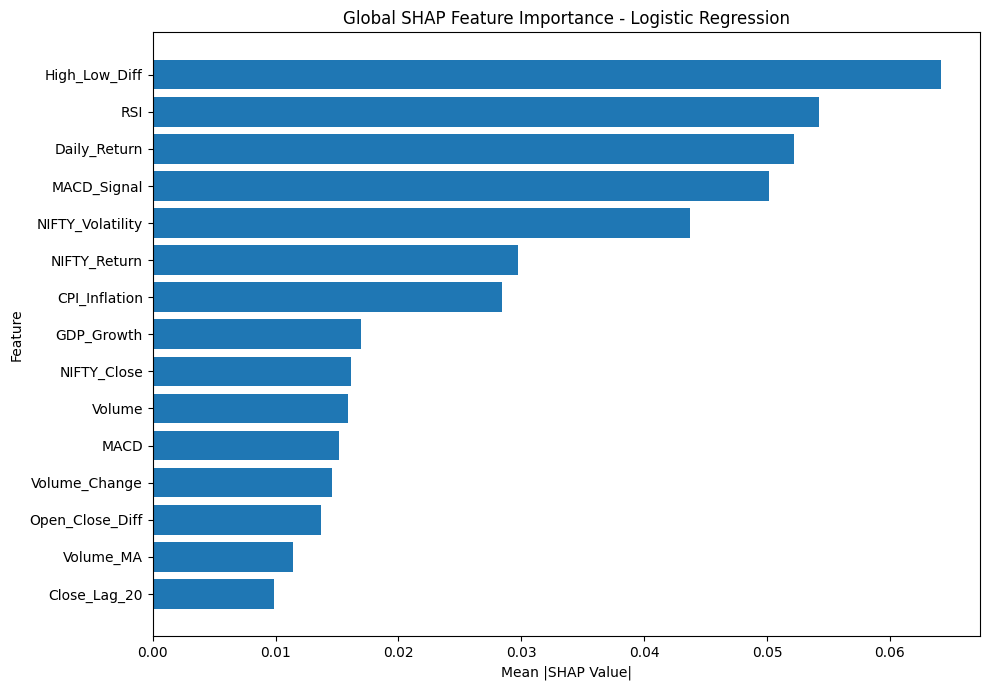

In [256]:
import matplotlib.pyplot as plt

top_n = 15

plot_df = shap_importance_df.head(top_n).sort_values(
    "Mean_Abs_SHAP"
)

plt.figure(figsize=(10, 7))

plt.barh(
    plot_df["Feature"],
    plot_df["Mean_Abs_SHAP"]
)

plt.xlabel("Mean |SHAP Value|")
plt.ylabel("Feature")
plt.title("Global SHAP Feature Importance - Logistic Regression")

plt.tight_layout()
plt.show()

**Class-specific SHAP importance<BR>
FOR BUY**

In [257]:
buy_importance = np.mean(
    np.abs(shap_values[:, :, 0]),
    axis=0
)

buy_shap_df = pd.DataFrame({
    "Feature": X_shap_scaled_df.columns,
    "Mean_Abs_SHAP": buy_importance
}).sort_values(
    "Mean_Abs_SHAP",
    ascending=False
)

buy_shap_df.head(10)

,Feature,Mean_Abs_SHAP
5,Daily_Return,0.077717
7,High_Low_Diff,0.057967
11,RSI,0.057146
13,MACD_Signal,0.048182
26,CPI_Inflation,0.026427
6,Open_Close_Diff,0.024989
4,Volume,0.024172
12,MACD,0.017228
25,NIFTY_Volatility,0.016865
22,Close_Lag_20,0.015020


**FOR HOLD**

In [258]:
hold_importance = np.mean(
    np.abs(shap_values[:, :, 1]),
    axis=0
)

hold_shap_df = pd.DataFrame({
    "Feature": X_shap_scaled_df.columns,
    "Mean_Abs_SHAP": hold_importance
}).sort_values(
    "Mean_Abs_SHAP",
    ascending=False
)

hold_shap_df.head(10)

,Feature,Mean_Abs_SHAP
7,High_Low_Diff,0.084989
11,RSI,0.064789
25,NIFTY_Volatility,0.055222
24,NIFTY_Return,0.039162
26,CPI_Inflation,0.033358
5,Daily_Return,0.024580
23,NIFTY_Close,0.017445
13,MACD_Signal,0.015984
6,Open_Close_Diff,0.015607
17,Volume_Change,0.010815


**FOR SELL**

In [259]:
sell_importance = np.mean(
    np.abs(shap_values[:, :, 2]),
    axis=0
)

sell_shap_df = pd.DataFrame({
    "Feature": X_shap_scaled_df.columns,
    "Mean_Abs_SHAP": sell_importance
}).sort_values(
    "Mean_Abs_SHAP",
    ascending=False
)

sell_shap_df.head(10)




,Feature,Mean_Abs_SHAP
13,MACD_Signal,0.086338
25,NIFTY_Volatility,0.059034
5,Daily_Return,0.054294
7,High_Low_Diff,0.049431
24,NIFTY_Return,0.048040
11,RSI,0.040690
27,GDP_Growth,0.029150
17,Volume_Change,0.027863
12,MACD,0.027248
26,CPI_Inflation,0.025461


**Global SHAP tells you which features are generally important.**

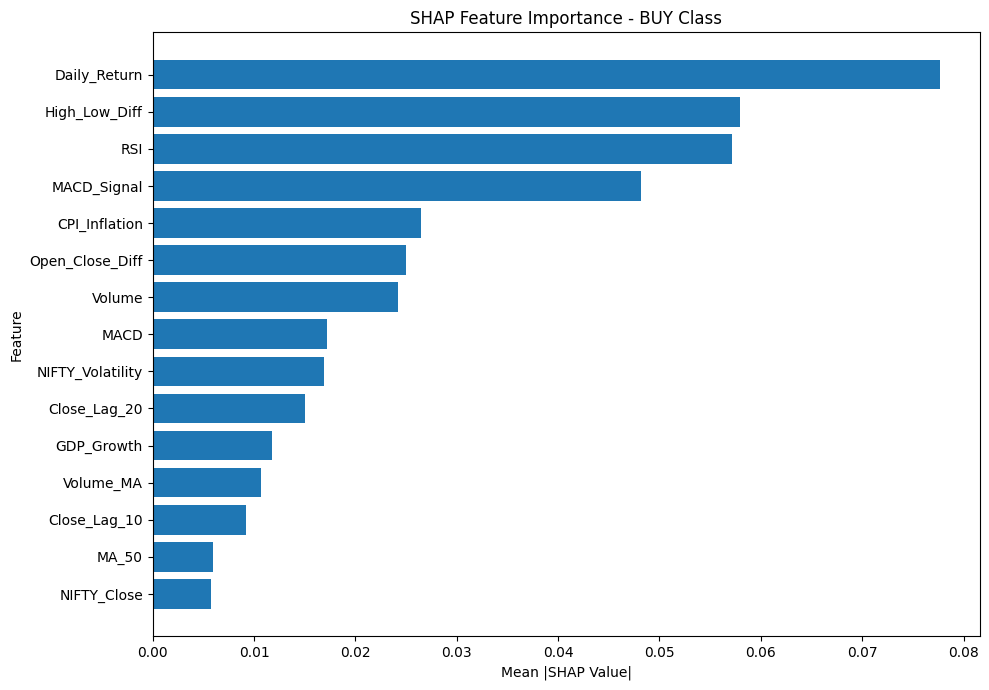

In [260]:
plt.figure(figsize=(10, 7))

plot_df = buy_shap_df.head(15).sort_values("Mean_Abs_SHAP")

plt.barh(
    plot_df["Feature"],
    plot_df["Mean_Abs_SHAP"]
)

plt.xlabel("Mean |SHAP Value|")
plt.ylabel("Feature")
plt.title("SHAP Feature Importance - BUY Class")

plt.tight_layout()
plt.show()

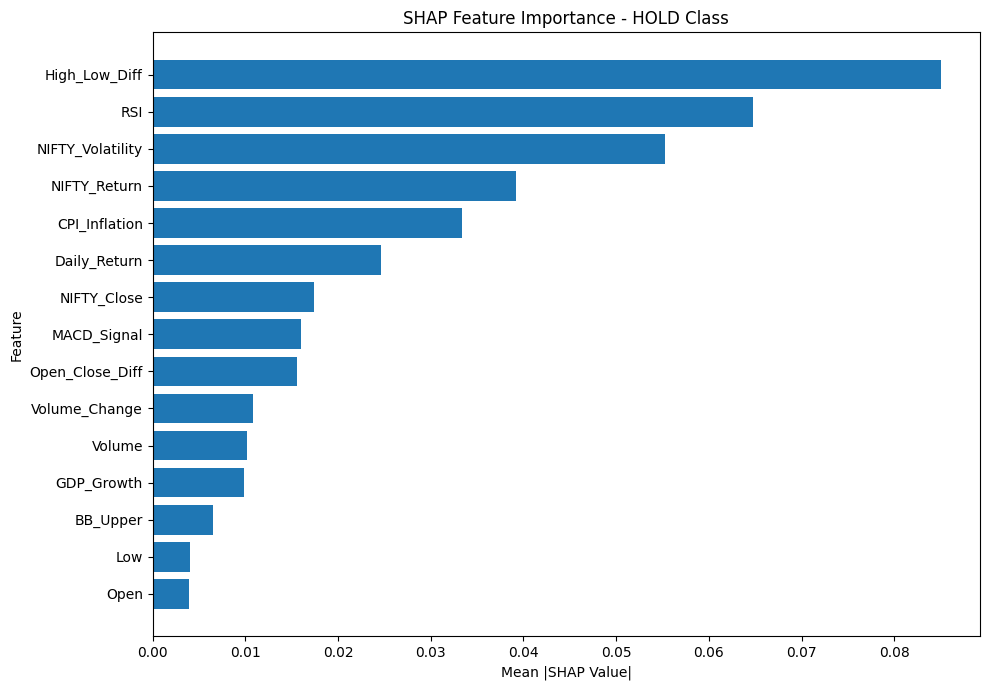

In [261]:
plt.figure(figsize=(10, 7))

plot_df = hold_shap_df.head(15).sort_values("Mean_Abs_SHAP")

plt.barh(
    plot_df["Feature"],
    plot_df["Mean_Abs_SHAP"]
)

plt.xlabel("Mean |SHAP Value|")
plt.ylabel("Feature")
plt.title("SHAP Feature Importance - HOLD Class")

plt.tight_layout()
plt.show()

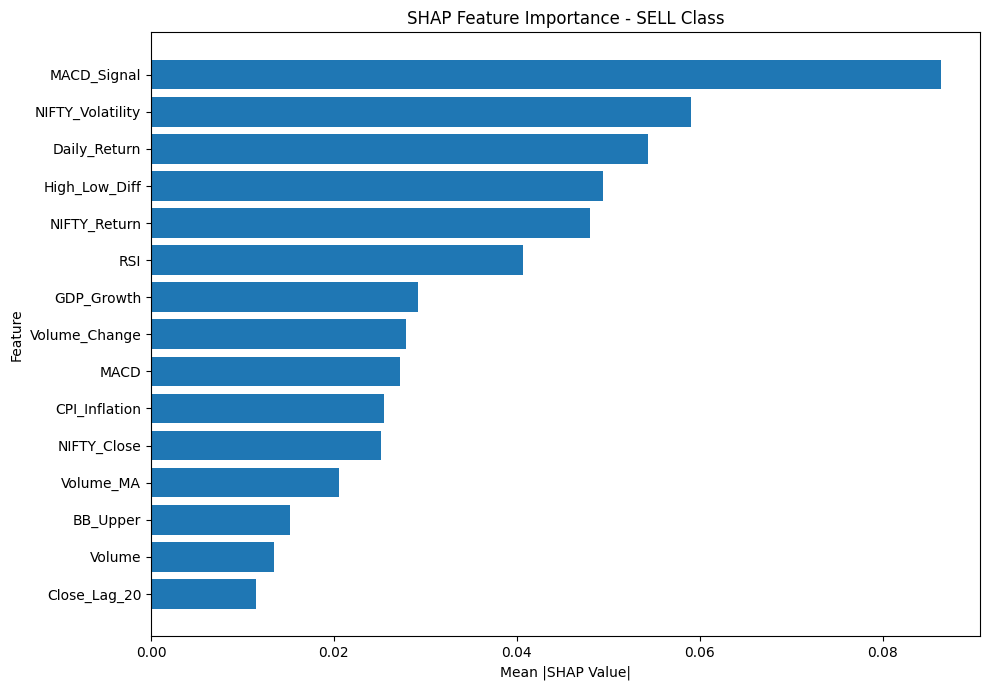

In [262]:
plt.figure(figsize=(10, 7))

plot_df = sell_shap_df.head(15).sort_values("Mean_Abs_SHAP")

plt.barh(
    plot_df["Feature"],
    plot_df["Mean_Abs_SHAP"]
)

plt.xlabel("Mean |SHAP Value|")
plt.ylabel("Feature")
plt.title("SHAP Feature Importance - SELL Class")

plt.tight_layout()
plt.show()

**Local SHAP answers:
“Why did the model make this particular prediction for this particular day?**

In [271]:
sample_idx = 150

sample = X_shap_scaled_df.iloc[[sample_idx]]

predicted_class = logistic_model.predict(sample)[0]
predicted_class_name = label_encoder.inverse_transform(
    [predicted_class]
)[0]

print("Predicted class:", predicted_class_name)

Predicted class: HOLD


In [272]:
sample_probability = logistic_model.predict_proba(sample)[0]

for class_name, probability in zip(
    label_encoder.classes_,
    sample_probability
):
    print(f"{class_name}: {probability:.4f}")

BUY: 0.2773
HOLD: 0.4793
SELL: 0.2434


In [273]:
predicted_class = int(predicted_class)

print("Predicted class index:", predicted_class)
print("Predicted class:", label_encoder.classes_[predicted_class])

Predicted class index: 1
Predicted class: HOLD


In [274]:
local_shap = shap_values_logistic[
    sample_idx, :, predicted_class
]
print(local_shap.shape)

(28,)


In [275]:
local_explanation_df = pd.DataFrame({
    "Feature": X_shap_scaled_df.columns,
    "Feature_Value": X_shap_scaled_df.iloc[sample_idx].values,
    "SHAP_Value": local_shap.values
})

local_explanation_df["Absolute_SHAP"] = (
    local_explanation_df["SHAP_Value"].abs()
)

local_explanation_df = (
    local_explanation_df
    .sort_values("Absolute_SHAP", ascending=False)
    .reset_index(drop=True)
)

local_explanation_df.head(10)

,Feature,Feature_Value,SHAP_Value,Absolute_SHAP
0,High_Low_Diff,-0.581877,0.106432,0.106432
1,NIFTY_Volatility,-0.439399,0.064094,0.064094
2,CPI_Inflation,-2.160743,-0.061799,0.061799
3,NIFTY_Close,2.894729,0.034244,0.034244
4,RSI,-0.279663,0.020429,0.020429
5,GDP_Growth,0.348255,0.014117,0.014117
6,MACD_Signal,-0.589830,-0.009718,0.009718
7,BB_Upper,0.919580,0.009130,0.009130
8,Daily_Return,0.112205,0.008669,0.008669
9,NIFTY_Return,0.075651,0.007412,0.007412


LOCAL SHAP EXPLANATION: BUY


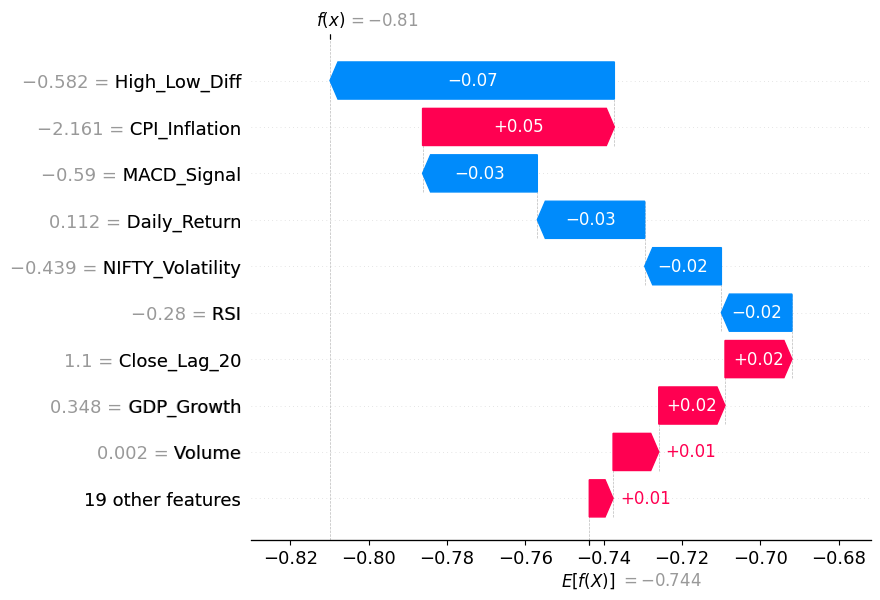

LOCAL SHAP EXPLANATION: HOLD


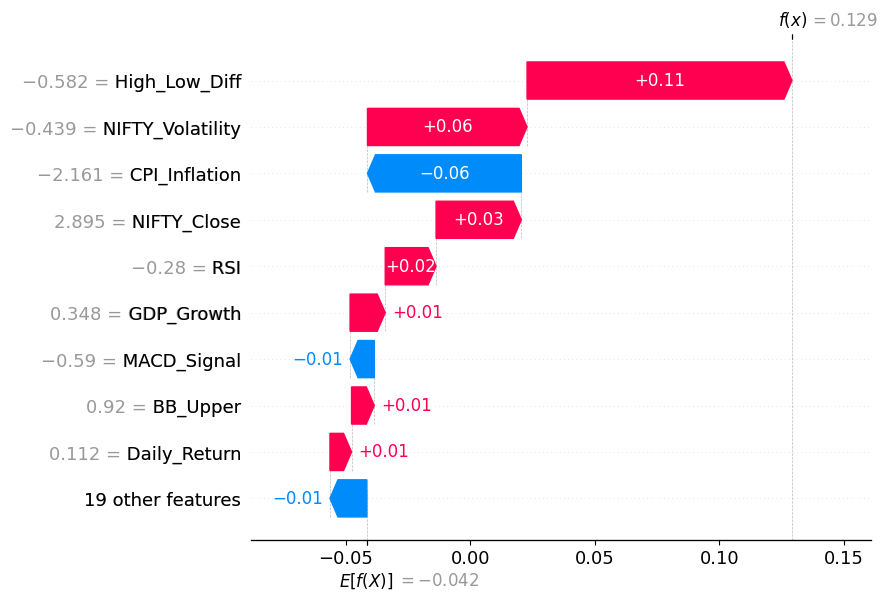

LOCAL SHAP EXPLANATION: SELL


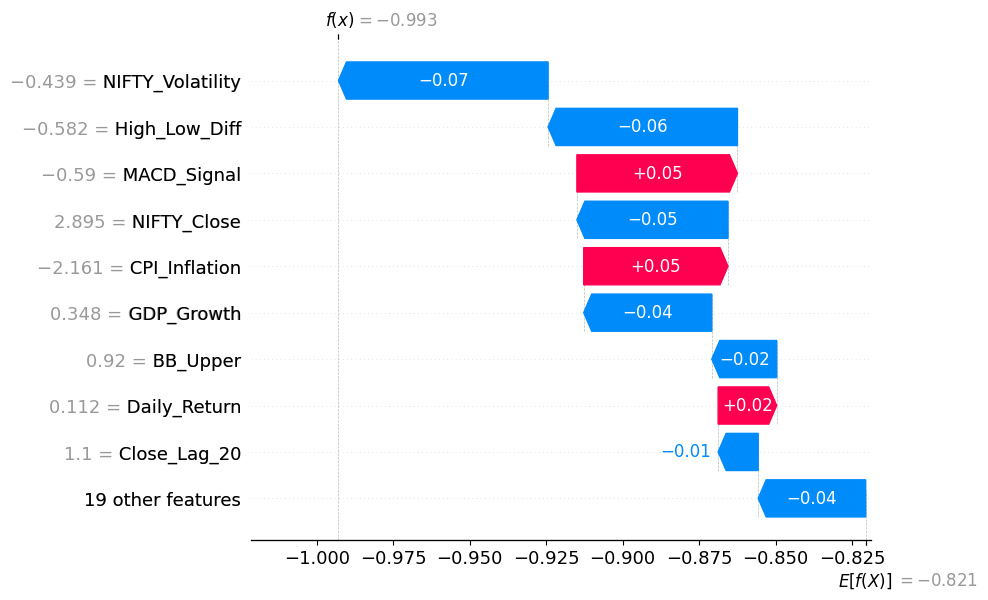

In [276]:
class_names = label_encoder.classes_

for class_idx, class_name in enumerate(class_names):

    print("=" * 60)
    print(f"LOCAL SHAP EXPLANATION: {class_name}")
    print("=" * 60)

    local_values = shap_values_logistic[
        sample_idx, :, class_idx
    ]

    explanation = shap.Explanation(
        values=local_values.values,
        base_values=shap_values_logistic.base_values[
            sample_idx, class_idx
        ],
        data=X_shap_scaled_df.iloc[sample_idx].values,
        feature_names=X_shap_scaled_df.columns
    )

    shap.plots.waterfall(
        explanation,
        max_display=10
    )